# From Words to Worlds · Milestone 1 + Text encoders compared without training

**Praniti Kale** · IE 7615 Deep Learning for AI · Generative project

This notebook has two parts. Part 1 is the complete Milestone 1 pipeline; Part 2 uses its captions to compare Transformer text encoders before any connector is trained.

**Part 1 (Sections 0–12)** covers Milestone 1 from scratch: it downloads the data, cleans and preprocesses it, builds and checks the text → embedding pipeline that conditions Stable Diffusion, and generates the first sample images. It also freezes the evaluation splits and prepares the object labels and stress prompts that later milestones are scored with, so every later number rests on data fixed here.

**Milestone 1 tasks and where they are done**

| Milestone 1 task | Section |
|---|---|
| Choose a dataset | 2 (MS-COCO 2017 val) |
| Clean and preprocess 1k–5k image–caption pairs | 3, 4, 5 (5,000 images, 25,000 captions) |
| Set up the environment (PyTorch + Diffusers + CLIP) | 0, 1 |
| Baseline notebook for the text → embedding pipeline | 10 |
| Sample prompt → image test runs | 11 (5 captions × 3 seeds, beside the real photos) |

**Contents**

| # | Section |
|---|---|
| 0 | Design choices and why |
| 1 | Setup |
| 2 | Download COCO val2017 |
| 3 | Captions: cleaning |
| 4 | Images: 512 × 512 |
| 5 | Data checks |
| 6 | Frozen splits |
| 7 | Object labels for every test caption |
| 8 | Stress prompts |
| 9 | Words CLIP splits into several tokens |
| 10 | Text → embedding |
| 11 | Stable Diffusion: first samples |
| 12 | Milestone 1 summary |
| **13** | **Part 2: text encoders compared without training** |
| 14 | Paraphrases, scene labels and word-order / colour triplets |
| 15 | Embedding the captions with CLIP, BERT, T5 and GPT-2 |
| 16 | How similar are the encoders? (linear CKA) |
| 17 | Do paraphrases land close together? |
| 18 | Do captions about the same kind of scene cluster? |
| 19 | Word order and colour binding |
| 20 | Combined summary |

**How to run.** Google Colab with a GPU (Runtime → Change runtime type → T4 GPU), then Run all (Part 1 takes about 25 minutes, most of it downloading and encoding). Sections 1 to 9 need no GPU. On Colab the COCO data goes to the fast local disk and every result is saved to Google Drive, so nothing is lost if the session resets.

## 0. Design choices and why

Every choice below either keeps later measurements fair or makes the work reproducible. Each is explained again where it is made.

**Data**

| Choice | Why |
|---|---|
| **MS-COCO 2017 validation split, all 5,000 photos** | Every caption comes with a real photo and boxes for 80 object types, so we can check whether a generated image shows what the caption names. It is the standard benchmark for text-to-image models, so results are comparable with published work. Using all 5,000 avoids hand-picking easy images. |
| **Captions cleaned lightly: spaces only, wording never changed** | Changing even a full stop changes the tokens CLIP reads, and so changes the image. Real users type imperfect prompts, and published results use the raw captions. Duplicate captions within an image are dropped; every change is counted. |
| **Center crop to a square, then resize to 512 × 512** | Stable Diffusion 1.5 paints at 512 × 512. Most COCO photos are wider than tall; stretching them would squash every object and make real photos look distorted next to generated ones. |
| **Saved as PNG** | JPEG adds compression marks that generated images do not have. Image-quality metrics would pick up that difference instead of real quality. PNG keeps real and generated images in the same lossless format. |
| **Photos with a short side under 256 px kept out of the real-photo reference set** | Enlarging them more than twice blurs them, which would unfairly penalise every generated image they are compared with. They stay in the caption data. |
| **EXIF rotation tags counted, not applied** | COCO's object boxes refer to the photo as stored. Rotating a photo moves the picture but not its boxes. The tagged photos are saved with their boxes drawn both ways so the choice can be checked by eye. |
| **Data problems counted, never fixed** (near-duplicates, caption quirks) | Removing or rewriting data would change the test set. Counting still shows how clean the data is. |

**Splits**

| Choice | Why |
|---|---|
| **A frozen 2,000-pair test split, fixed seed** | Every setting in later milestones is scored on exactly the same captions, so differences come from the setting, not the captions. The seed makes it reproducible. |
| **A separate 500-pair development split** | Settings (guidance, scheduler, steps) are chosen on this split and only reported on the test split. Choosing on the test split would make the best setting look good partly by luck. |
| **A second, disjoint set of 2,000 real photos** | FID depends strongly on how many images are scored, so an FID value is only meaningful beside the FID that real photos get against other real photos at the same count. That needs two separate sets of real photos. |

**Object labels and stress prompts**

| Choice | Why |
|---|---|
| **Every test caption mapped to the COCO objects it names** | To ask "did the model draw the dog?", the code must know the caption names a dog. Captions say "puppies", "men" or "a teddy bear", not COCO's exact names, so the mapping handles plurals, people words, synonyms and two-word names. |
| **Unclear words marked and excluded** (orange, mouse, tie, glass…) | "An orange cat" contains no fruit. Counting such words would blame the model for objects that were never asked for. |
| **Crop check: an object counts only if half its box survives the crop** | If the crop cut the object out of the real photo, it is unfair to count a missing object against the model. |
| **200 stress prompts with their expected answers** | Natural captions rarely test counting, colour binding, spatial relations or word order. Storing the expected answer lets a script check them instead of judging by eye. |

**Text → embedding and samples**

| Choice | Why |
|---|---|
| **Stable Diffusion 1.5's own tokenizer and text encoder (CLIP ViT-L/14)** | These are exactly what the UNet was trained to read, so the embeddings we build are the ones that condition the model. |
| **Captions encoded one at a time, no attention mask** | This is how the pipeline encodes a prompt. Half-precision GPU arithmetic gives slightly different numbers in large batches, and 30 denoising steps amplify that into visibly different images. |
| **Embeddings cached once** | Every later experiment reads the same embeddings, saving time and guaranteeing identical conditioning. |
| **Image from cached embeddings vs image from raw text** | Proves the pipeline we built is the one driving the model: the two images should be identical. |
| **Retrieval check** | If the embeddings carry meaning, a caption's own photo should rank near the top among 2,000 photos, far above chance (1 in 2,000). |
| **Samples generated from the cached embeddings, beside the real photo, 3 seeds each** | Shows the pipeline end to end; the real photo shows what the caption describes; three seeds show the variation. |
| **Stable Diffusion's defaults for the samples** (PNDM scheduler, 30 steps, guidance 7.5) | A neutral, widely used baseline; tuning these is Milestone 2. |

## Install
Run once per session. Locally: install PyTorch for your CUDA version first.

In [1]:
# Run once per session. Locally: install PyTorch for your CUDA version first, then this.
%pip install -q -U diffusers transformers accelerate safetensors ftfy sentencepiece scikit-learn clean-fid torch-fidelity

## 1. Setup

In [2]:
import os, sys, re, json, math, time, random, shutil, zipfile, platform, textwrap, warnings
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from PIL import Image, ImageDraw, ImageOps
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


@dataclass
class Config:
    # data
    seed_eval: int = 2026
    seed_dev: int = 2027
    seed_ref: int = 2028
    seed_stress: int = 2030
    image_size: int = 512
    min_short_side: int = 256        # smaller photos would be enlarged > 2x and blur: kept out of the real reference set
    n_eval: int = 2000
    n_dev: int = 500
    n_ref_b: int = 2000
    # object labels
    min_box_kept: float = 0.5        # a named object counts only if half its box survives the crop
    min_cover: float = 0.005         # ... and the kept part covers at least 0.5% of the image
    # models
    clip_id: str = "openai/clip-vit-large-patch14"
    sd_id: str = "stable-diffusion-v1-5/stable-diffusion-v1-5"
    # first samples (Stable Diffusion's defaults)
    steps: int = 30
    guidance: float = 7.5
    sample_seeds: tuple = (0, 1, 2)


CFG = Config()

IN_COLAB = "google.colab" in sys.modules
USE_DRIVE = True                     # Colab only: save results and sample images to Google Drive
if "W2W_ROOT" in os.environ:         # lets the notebook be pointed anywhere (used for testing)
    DATA = RESULTS_ROOT = Path(os.environ["W2W_ROOT"])
elif IN_COLAB:
    DATA = Path("/content/w2w_data")
    RESULTS_ROOT = Path("/content/w2w_results")
    if USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        RESULTS_ROOT = Path("/content/drive/MyDrive/w2w_praniti")
else:
    DATA = RESULTS_ROOT = Path.cwd() / "w2w_praniti"

COCO = DATA / "coco"
IMAGES_DIR = COCO / "val2017"
ANN_DIR = COCO / "annotations"
CAP_JSON = ANN_DIR / "captions_val2017.json"
INST_JSON = ANN_DIR / "instances_val2017.json"
PROC_DIR = COCO / "val2017_512"
RESULTS = RESULTS_ROOT / "results"
FIGS = RESULTS / "figures"
SPLITS = RESULTS / "splits"
SAMPLES = RESULTS_ROOT / "samples"
for p in (COCO, PROC_DIR, RESULTS, FIGS, SPLITS, SAMPLES):
    p.mkdir(parents=True, exist_ok=True)

json.dump(asdict(CFG), open(RESULTS / "config.json", "w"), indent=2)
print("data   :", DATA)
print("results:", RESULTS_ROOT)
print(json.dumps(asdict(CFG), indent=2))


def savefig(name):
    plt.savefig(FIGS / f"{name}.png", bbox_inches="tight", dpi=140)

Mounted at /content/drive
data   : /content/w2w_data
results: /content/drive/MyDrive/w2w_praniti
{
  "seed_eval": 2026,
  "seed_dev": 2027,
  "seed_ref": 2028,
  "seed_stress": 2030,
  "image_size": 512,
  "min_short_side": 256,
  "n_eval": 2000,
  "n_dev": 500,
  "n_ref_b": 2000,
  "min_box_kept": 0.5,
  "min_cover": 0.005,
  "clip_id": "openai/clip-vit-large-patch14",
  "sd_id": "stable-diffusion-v1-5/stable-diffusion-v1-5",
  "steps": 30,
  "guidance": 7.5,
  "sample_seeds": [
    0,
    1,
    2
  ]
}


## 2. Download COCO val2017

The 2017 validation split: 5,000 photos (about 0.8 GB), five human captions each, and boxes for 80 object categories (about 0.25 GB of annotations). The downloads resume: a file already on disk is not fetched again.

In [3]:
IMAGES_URL = "http://images.cocodataset.org/zips/val2017.zip"
ANN_URL = "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"


def download(url, dest):
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    tmp = dest.with_suffix(dest.suffix + ".part")
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        with open(tmp, "wb") as f, tqdm(total=total, unit="B", unit_scale=True, desc=dest.name) as bar:
            for chunk in r.iter_content(chunk_size=1 << 20):
                f.write(chunk)
                bar.update(len(chunk))
    tmp.rename(dest)
    return dest


have_images = IMAGES_DIR.exists() and any(IMAGES_DIR.iterdir())
if not have_images:
    with zipfile.ZipFile(download(IMAGES_URL, COCO / "val2017.zip")) as z:
        z.extractall(COCO)
if not (CAP_JSON.exists() and INST_JSON.exists()):
    with zipfile.ZipFile(download(ANN_URL, COCO / "annotations_trainval2017.zip")) as z:
        z.extractall(COCO, [m for m in z.namelist() if m.endswith(("captions_val2017.json", "instances_val2017.json"))])

caps_json = json.load(open(CAP_JSON, encoding="utf-8"))
inst_json = json.load(open(INST_JSON, encoding="utf-8"))
print(f"{len(caps_json['images']):,} images, {len(caps_json['annotations']):,} captions, "
      f"{len(inst_json['annotations']):,} object boxes in {len(inst_json['categories'])} categories")

val2017.zip:   0%|          | 0.00/816M [00:00<?, ?B/s]

annotations_trainval2017.zip:   0%|          | 0.00/253M [00:00<?, ?B/s]

5,000 images, 25,014 captions, 36,781 object boxes in 80 categories


## 3. Captions: cleaning

COCO captions were typed by crowd workers, so they carry stray newlines, double spaces and a space before the full stop. Cleaning fixes only those and drops exact duplicates within an image. **Wording, spelling and case are never changed**: the prompts must stay the captions everyone else evaluates on, and a changed full stop changes the CLIP tokens and therefore the image.

In [4]:
_WS = re.compile(r"\s+")


def clean_caption(text):
    t = _WS.sub(" ", text.replace("\n", " ")).strip()
    return re.sub(r"\s+([.,!?;:])", r"\1", t)


assert clean_caption("A man  riding\na wave .") == "A man riding a wave."
assert clean_caption("A plate of food with brocolli.") == "A plate of food with brocolli."   # spelling kept


def build_manifest(caps_json, inst_json):
    # one row per image: size, cleaned captions, object categories
    cat_name = {c["id"]: c["name"] for c in inst_json["categories"]}
    captions_by_image, cats_by_image = {}, {}
    for a in caps_json["annotations"]:
        captions_by_image.setdefault(a["image_id"], []).append(a["caption"])
    for a in inst_json["annotations"]:
        cats_by_image.setdefault(a["image_id"], set()).add(cat_name[a["category_id"]])
    log, rows = Counter(), []
    for im in caps_json["images"]:
        raw = captions_by_image.get(im["id"], [])
        cleaned, seen = [], set()
        for c in raw:
            cc = clean_caption(c)
            if cc != c:
                log["captions_whitespace_fixed"] += 1
            if not cc:
                log["captions_empty_dropped"] += 1
                continue
            if cc.lower() in seen:
                log["captions_duplicate_dropped"] += 1
                continue
            seen.add(cc.lower())
            cleaned.append(cc)
        rows.append({"image_id": im["id"], "file_name": im["file_name"], "width": im["width"],
                     "height": im["height"], "n_captions_raw": len(raw), "captions": cleaned,
                     "n_captions": len(cleaned), "categories": sorted(cats_by_image.get(im["id"], set()))})
    df = pd.DataFrame(rows).sort_values("image_id").reset_index(drop=True)
    log["images"] = len(df)
    log["captions_raw"] = int(df.n_captions_raw.sum())
    log["captions_kept"] = int(df.n_captions.sum())
    return df, dict(log)


def caption_table(df):
    # one row per caption, with a stable index that the embedding cache uses for its rows
    out = df.explode("captions").rename(columns={"captions": "caption"}).dropna(subset=["caption"])
    out = out[["image_id", "file_name", "caption"]].reset_index(drop=True)
    out.insert(0, "caption_idx", range(len(out)))
    return out


manifest, cleaning_log = build_manifest(caps_json, inst_json)
caps = caption_table(manifest)
manifest.to_json(RESULTS / "manifest.jsonl", orient="records", lines=True)
caps.to_csv(RESULTS / "captions.csv", index=False)
print(json.dumps(cleaning_log, indent=2))

{
  "captions_whitespace_fixed": 3832,
  "captions_duplicate_dropped": 10,
  "images": 5000,
  "captions_raw": 25014,
  "captions_kept": 25004
}


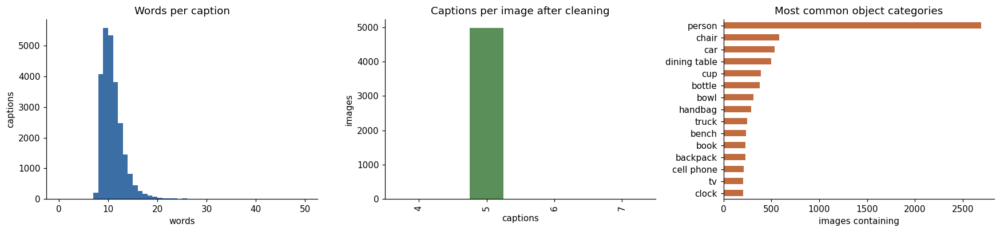

median 10 words, longest 49; 48 images have no labelled object


In [5]:
words = caps.caption.str.split().str.len()
per_image = manifest.n_captions
cat_counts = pd.Series([c for cs in manifest.categories for c in cs]).value_counts()

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].hist(words, bins=range(0, int(words.max()) + 2), color="#3b6ea5")
ax[0].set(title="Words per caption", xlabel="words", ylabel="captions")
per_image.value_counts().sort_index().plot.bar(ax=ax[1], color="#5a8f5a")
ax[1].set(title="Captions per image after cleaning", xlabel="captions", ylabel="images")
cat_counts.head(15)[::-1].plot.barh(ax=ax[2], color="#c06c3e")
ax[2].set(title="Most common object categories", xlabel="images containing")
plt.tight_layout(); savefig("01_caption_stats"); plt.show()
print(f"median {words.median():.0f} words, longest {words.max()}; "
      f"{(manifest.categories.map(len) == 0).sum()} images have no labelled object")

## 4. Images: 512 × 512

Stable Diffusion 1.5 paints at 512 × 512, so every real photo is brought to the same size: convert to RGB, **center-crop to a square, then resize** with Lanczos. Never stretch: COCO photos are mostly 4:3 or wider, and squashing would distort shapes and bias every image metric. Saved as PNG so real and generated images go through the same lossless format before any metric sees them.

While each photo is open, the same pass records its original size and mode, any EXIF orientation tag, how much of the frame the crop keeps, and a 256-bit difference hash for the duplicate check in Section 5.

In [6]:
ORIENTATION_TAG = 274


def center_square(img, size):
    w, h = img.size
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return img.crop((left, top, left + s, top + s)).resize((size, size), Image.LANCZOS)


def dhash_bits(img, size=16):
    g = np.asarray(img.convert("L").resize((size + 1, size), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()


def png_path(file_name):
    return PROC_DIR / (Path(file_name).stem + ".png")


def process_one(r):
    out = png_path(r.file_name)
    with Image.open(IMAGES_DIR / r.file_name) as im:
        mode, (w, h) = im.mode, im.size
        try:
            orient = int(im.getexif().get(ORIENTATION_TAG, 1))
        except Exception:
            orient = 1
        rgb = im.convert("RGB")
    bits = dhash_bits(rgb)
    if not out.exists():
        tmp = out.with_name(out.stem + ".tmp.png")
        center_square(rgb, CFG.image_size).save(tmp)
        tmp.replace(out)                    # atomic: an interrupted run never leaves a broken PNG
    s = min(w, h)
    return {"image_id": r.image_id, "file_512": out.name, "mode_in": mode, "w": w, "h": h,
            "exif_orientation": orient, "crop_fraction_kept": round(s * s / (w * h), 4),
            "reference_eligible": s >= CFG.min_short_side, "hash": np.packbits(bits)}


with ThreadPoolExecutor(max_workers=8) as pool:
    results = list(tqdm(pool.map(process_one, manifest.itertuples()), total=len(manifest), desc="512 x 512"))
pre = pd.DataFrame(results)
HASHES = np.stack([np.unpackbits(h) for h in pre.pop("hash")]).astype(bool)
pre.to_csv(RESULTS / "preprocess_log.csv", index=False)

assert (pre.w.values == manifest.width.values).all() and (pre.h.values == manifest.height.values).all(), \
    "file sizes disagree with the annotation file"
print(f"converted to RGB: {(pre.mode_in != 'RGB').sum()}  |  crop keeps {pre.crop_fraction_kept.mean():.1%} "
      f"of a frame on average (min {pre.crop_fraction_kept.min():.1%})  |  "
      f"reference-eligible: {pre.reference_eligible.sum():,}, excluded small: {(~pre.reference_eligible).sum()}")

512 x 512:   0%|          | 0/5000 [00:00<?, ?it/s]

converted to RGB: 10  |  crop keeps 71.6% of a frame on average (min 24.8%)  |  reference-eligible: 4,958, excluded small: 42


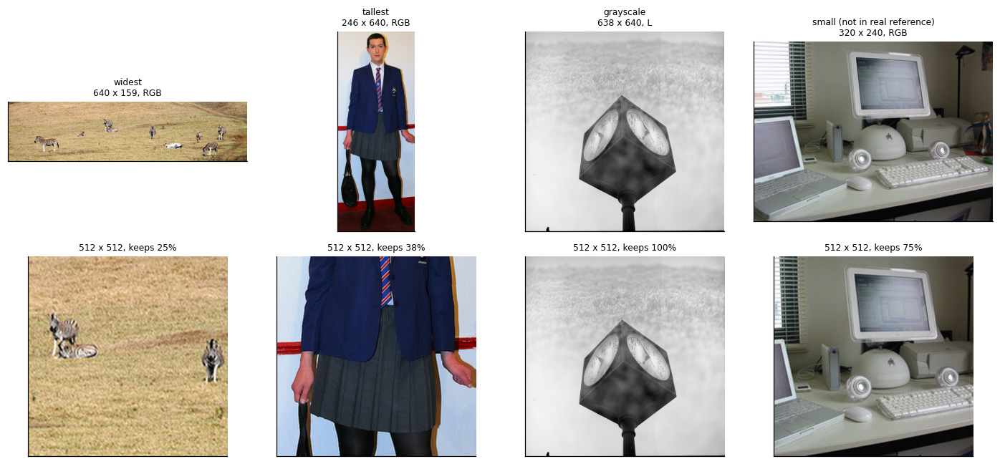

In [7]:
aspect = pre.w / pre.h
picks = [("widest", pre.loc[aspect.idxmax()]), ("tallest", pre.loc[aspect.idxmin()])]
if (pre.mode_in != "RGB").any():
    picks.append(("grayscale", pre[pre.mode_in != "RGB"].iloc[0]))
if (~pre.reference_eligible).any():
    picks.append(("small (not in real reference)", pre[~pre.reference_eligible].iloc[0]))
names = dict(zip(manifest.image_id, manifest.file_name))
fig, ax = plt.subplots(2, len(picks), figsize=(3.2 * len(picks), 6), squeeze=False)
for j, (label, r) in enumerate(picks):
    ax[0, j].imshow(Image.open(IMAGES_DIR / names[r.image_id]).convert("RGB"))
    ax[0, j].set_title(f"{label}\n{r.w} x {r.h}, {r.mode_in}", fontsize=8)
    ax[1, j].imshow(Image.open(PROC_DIR / r.file_512))
    ax[1, j].set_title(f"512 x 512, keeps {r.crop_fraction_kept:.0%}", fontsize=8)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); savefig("02_preprocessing_examples"); plt.show()

## 5. Data checks: counted, never changed

1. **EXIF orientation.** Some photos carry a hidden "rotate me" tag. This notebook does not apply it. If a tagged photo were rotated, its COCO boxes might stop lining up. Each tagged photo is saved with its boxes drawn on the stored and on the rotated pixels, so the fit can be checked by eye.
2. **Near-duplicate photos.** Two photos whose 256-bit hashes differ in 12 bits or fewer. Duplicates inside the real reference set make FID look slightly better than it is.
3. **Caption quirks kept on purpose**: repeated words ("a a dog"), no final punctuation, lower-case start, very short, non-ASCII.

In [8]:
_REPEAT = re.compile(r"\b(\w+)\s+\1\b", re.IGNORECASE)


def near_duplicate_pairs(hashes, max_hamming=12):
    b = hashes.astype(np.float32) * 2 - 1
    dist = (b.shape[1] - b @ b.T) / 2
    i, j = np.where(np.triu(dist <= max_hamming, k=1))
    return [(int(a), int(c), int(dist[a, c])) for a, c in zip(i, j)]


def caption_quirks(captions):
    caps_ = list(captions)
    rep = [c for c in caps_ if _REPEAT.search(c)]
    return {"captions": len(caps_), "repeated_word": len(rep), "repeated_word_examples": rep[:5],
            "no_final_punctuation": sum(1 for c in caps_ if c and c[-1] not in ".!?"),
            "starts_lower_case": sum(1 for c in caps_ if c[:1].islower()),
            "under_5_words": sum(1 for c in caps_ if len(c.split()) < 5),
            "non_ascii": sum(1 for c in caps_ if any(ord(ch) > 127 for ch in c))}


BOXES = defaultdict(list)
CAT_NAME = {c["id"]: c["name"] for c in inst_json["categories"]}
for a in inst_json["annotations"]:
    BOXES[a["image_id"]].append((CAT_NAME[a["category_id"]], a["bbox"], a.get("iscrowd", 0)))

tagged = pre[pre.exif_orientation != 1]
exif_dir = FIGS / "exif_check"
for r in tagged.head(12).itertuples():
    with Image.open(IMAGES_DIR / names[r.image_id]) as im:
        panels = [im.convert("RGB"), ImageOps.exif_transpose(im).convert("RGB")]
    for p in panels:
        d = ImageDraw.Draw(p)
        for _, (x, y, w, h), _ in BOXES[r.image_id]:
            d.rectangle([x, y, x + w, y + h], outline=(255, 0, 0), width=3)
    canvas = Image.new("RGB", (panels[0].width + panels[1].width, max(p.height for p in panels)), "white")
    canvas.paste(panels[0], (0, 0)); canvas.paste(panels[1], (panels[0].width, 0))
    exif_dir.mkdir(exist_ok=True)
    canvas.save(exif_dir / f"{r.image_id}_stored_left_rotated_right.jpg", quality=85)

ids = pre.image_id.tolist()
dups = near_duplicate_pairs(HASHES)
checks = {
    "exif_orientation": {"tagged_images": int(len(tagged)),
                         "by_value": {str(k): int(v) for k, v in tagged.exif_orientation.value_counts().items()},
                         "overlays": str(exif_dir) if len(tagged) else None},
    "near_duplicates": {"pairs": len(dups), "examples": [(ids[i], ids[j], d) for i, j, d in dups[:20]],
                        "rule": "256-bit difference hash, Hamming distance <= 12"},
    "caption_quirks_kept_on_purpose": caption_quirks(caps.caption),
}
json.dump(checks, open(RESULTS / "data_checks.json", "w"), indent=2, default=int)
print(json.dumps(checks, indent=2, default=int))

if dups:
    show = dups[:3]
    fig, ax = plt.subplots(len(show), 2, figsize=(6, 3 * len(show)), squeeze=False)
    for row, (i, j, d) in enumerate(show):
        for col, k in enumerate((i, j)):
            ax[row, col].imshow(Image.open(PROC_DIR / pre.file_512[k])); ax[row, col].axis("off")
            ax[row, col].set_title(f"id {ids[k]}  (distance {d})", fontsize=8)
    plt.tight_layout(); savefig("03_near_duplicates"); plt.show()

{
  "exif_orientation": {
    "tagged_images": 0,
    "by_value": {},
    "overlays": null
  },
  "near_duplicates": {
    "pairs": 0,
    "examples": [],
    "rule": "256-bit difference hash, Hamming distance <= 12"
  },
  "caption_quirks_kept_on_purpose": {
    "captions": 25004,
    "repeated_word": 33,
    "repeated_word_examples": [
      "Cars are parked on the the street in front of the building.",
      "A man holding holding a giant remote control.",
      "a may leading a a boy on a pony with a rope",
      "View from an airplane looking looking out over large parking lot.",
      "A dog in a a cage with a bed and bowl"
    ],
    "no_final_punctuation": 6234,
    "starts_lower_case": 3708,
    "under_5_words": 0,
    "non_ascii": 0
  }
}


## 6. Frozen splits

| Split | What | Used for |
|---|---|---|
| `eval_2000` | 2,000 reference-eligible images, one random caption each, seed 2026 | **Reported numbers** in every later milestone |
| `eval_500` | first 500 rows of `eval_2000` | variance across seeds only, **never tuning** (it is inside the test split) |
| `dev_500` | 500 eligible images **outside** `eval_2000`, seed 2027 | choosing guidance, scheduler and thresholds |
| `real_ref_b_2000` | 2,000 eligible images outside `eval_2000`, seed 2028 | the real-against-real FID floor: FID between two disjoint sets of real photos at the same N |

FID shrinks a lot with sample size, so a generated FID only means something next to the score real photos get at the same N. `dev_500` and `real_ref_b_2000` may share photos: the reference set only contributes pixels, never captions.

In [9]:
def draw_eval(eligible_ids, caps, n, seed):
    # sample 2,000 eligible images with a fixed seed, then one random caption of each
    rng = random.Random(seed)
    chosen = rng.sample(sorted(eligible_ids), n)
    rows = []
    for iid in chosen:
        options = caps.loc[caps.image_id == iid, "caption_idx"].tolist()
        ci = rng.choice(options)
        rows.append({"image_id": iid, "caption_idx": ci, "caption": caps.loc[caps.caption_idx == ci, "caption"].item()})
    return pd.DataFrame(rows)


def draw_outside(eligible_ids, exclude, caps, n, seed, with_caption=True):
    rng = random.Random(seed)
    pool = sorted(set(eligible_ids) - set(exclude))
    if len(pool) < n:
        raise ValueError(f"only {len(pool)} eligible images outside the test split, need {n}")
    chosen = rng.sample(pool, n)
    if not with_caption:
        return pd.DataFrame({"image_id": sorted(chosen)})
    by_image = caps.groupby("image_id")
    rows = []
    for iid in chosen:
        g = by_image.get_group(iid)
        ci = rng.choice(g.caption_idx.tolist())
        rows.append({"image_id": iid, "caption_idx": ci, "caption": g.loc[g.caption_idx == ci, "caption"].item()})
    return pd.DataFrame(rows)


eligible = pre.loc[pre.reference_eligible, "image_id"].tolist()
ev = draw_eval(eligible, caps, CFG.n_eval, CFG.seed_eval)
dev = draw_outside(eligible, ev.image_id, caps, CFG.n_dev, CFG.seed_dev)
refb = draw_outside(eligible, ev.image_id, caps, CFG.n_ref_b, CFG.seed_ref, with_caption=False)

e, d, b = set(ev.image_id), set(dev.image_id), set(refb.image_id)
assert not e & d and not e & b, "a split overlaps the test split"
assert ev.image_id.is_unique and dev.image_id.is_unique and refb.image_id.is_unique
assert draw_eval(eligible, caps, CFG.n_eval, CFG.seed_eval).equals(ev), "split is not reproducible"

for name, frame in {"eval_2000": ev, "eval_500": ev.head(500), "dev_500": dev, "real_ref_b_2000": refb}.items():
    frame.to_csv(SPLITS / f"{name}.csv", index=False, lineterminator="\n")
splits_info = {"test": len(e), "dev": len(d), "real_ref_b": len(b), "dev_and_ref_b_shared": len(d & b),
               "first_eval_pairs": ev.head(3).to_dict("records")}
print(json.dumps(splits_info, indent=2, default=str))

{
  "test": 2000,
  "dev": 500,
  "real_ref_b": 2000,
  "dev_and_ref_b_shared": 353,
  "first_eval_pairs": [
    {
      "image_id": 117492,
      "caption_idx": 4924,
      "caption": "A group of people, mostly children, are gathering around a tent."
    },
    {
      "image_id": 304404,
      "caption_idx": 13187,
      "caption": "An organized baseball match between two teams with the batter swinging"
    },
    {
      "image_id": 479099,
      "caption_idx": 20753,
      "caption": "A far away bench covers all the distant serenity of a beautiful flower garden."
    }
  ]
}


## 7. Object labels for every test caption

Later milestones measure object recall, which needs "the caption names X and the real photo shows X". Two things make that harder than it looks:

* **Words are not categories.** "Two men riding bikes past the buses" names *person*, *bicycle* and *bus*. The table below handles plurals, people words, synonyms (*puppy* → dog, *sofa* → couch) and two-word names, which are tried first so *teddy bear* never also counts as *bear* and *hot dog* never as *dog*. Words that often mean something else (*orange*, *mouse*, *tie*, *glass*, *keyboard*, *bat*, *ball*, *table*, *plant*) are kept but marked **ambiguous** and left out of the scoring; *orange* in front of another noun ("an orange cat") is read as a colour.
* **The crop can remove the object.** If the dog was at the edge of a wide photo, the 512 × 512 square may not show it. A named object counts as a **target** only if its best box keeps at least half its area after the crop and the kept part covers at least 0.5% of the image.

In [10]:
COCO_CLASSES = [c["name"] for c in sorted(inst_json["categories"], key=lambda c: c["id"])]
SYNONYMS = {
    "bike": "bicycle", "motorbike": "motorcycle", "moped": "motorcycle", "scooter": "motorcycle",
    "plane": "airplane", "jet": "airplane", "aircraft": "airplane", "airliner": "airplane",
    "taxi": "car", "sedan": "car", "suv": "car", "sailboat": "boat", "ship": "boat", "canoe": "boat",
    "kayak": "boat", "yacht": "boat", "ferry": "boat", "stoplight": "traffic light", "hydrant": "fire hydrant",
    "puppy": "dog", "kitten": "cat", "kitty": "cat", "pony": "horse", "lamb": "sheep", "cattle": "cow",
    "bull": "cow", "pigeon": "bird", "seagull": "bird", "gull": "bird", "duck": "bird", "goose": "bird",
    "parrot": "bird", "swan": "bird", "teddy": "teddy bear",
    "necktie": "tie", "luggage": "suitcase", "purse": "handbag", "racket": "tennis racket",
    "racquet": "tennis racket", "mitt": "baseball glove", "bat": "baseball bat", "glove": "baseball glove",
    "ski": "skis", "surf board": "surfboard", "skate board": "skateboard", "soccer ball": "sports ball",
    "tennis ball": "sports ball", "baseball": "sports ball", "football": "sports ball",
    "basketball": "sports ball", "ball": "sports ball",
    "mug": "cup", "doughnut": "donut", "hotdog": "hot dog", "stove": "oven", "fridge": "refrigerator",
    "plant": "potted plant", "houseplant": "potted plant", "table": "dining table",
    "sofa": "couch", "television": "tv", "monitor": "tv", "phone": "cell phone", "cellphone": "cell phone",
    "smartphone": "cell phone", "remote control": "remote", "controller": "remote",
    "hairdryer": "hair drier", "hair dryer": "hair drier", "blow dryer": "hair drier",
}
PERSON_WORDS = {
    "person", "man", "woman", "people", "boy", "girl", "child", "kid", "guy", "lady", "baby", "toddler",
    "adult", "player", "skier", "surfer", "skateboarder", "snowboarder", "rider", "biker", "cyclist",
    "chef", "cook", "batter", "pitcher", "catcher", "umpire", "crowd", "someone", "gentleman",
    "teenager", "teen", "student", "worker", "officer", "policeman", "soldier", "couple", "family",
    "friend", "mother", "father", "son", "daughter", "he", "she",
}
AMBIGUOUS = {"orange", "mouse", "tie", "glass", "keyboard", "bat", "glove", "table", "plant", "ball",
             "baseball", "football", "bull", "ski", "controller", "monitor"}
IRREGULAR = {"men": "man", "women": "woman", "children": "child", "people": "people", "knives": "knife",
             "mice": "mouse", "geese": "goose", "skis": "skis", "scissors": "scissors", "sheep": "sheep",
             "cattle": "cattle", "glasses": "glass", "buses": "bus", "benches": "bench",
             "sandwiches": "sandwich", "couches": "couch", "ladies": "lady", "babies": "baby",
             "puppies": "puppy", "kitties": "kitty", "ponies": "pony", "teddies": "teddy", "guys": "guy"}
NOT_ADJECTIVE_AFTER = {"", "and", "or", "on", "in", "with", "of", "next", "near", "by", "at", "is", "are",
                       "sitting", "slices", "slice", "juice", "halves", "peel", "tree", "trees"}
STOPWORDS = {"a", "an", "the", "of", "on", "in", "at", "to", "with", "and", "is", "are", "its", "it", "for",
             "by", "some", "very", "while", "into", "that", "this", "there", "his", "her", "their", "from",
             "next", "up", "down", "near", "over", "through", "each", "other", "around", "another", "be",
             "being", "has", "have"}
_CLASSES = set(COCO_CLASSES)
_TERMS = _CLASSES | set(SYNONYMS) | PERSON_WORDS


def words_of(caption):
    out = [w.strip(".,!?;:'\"()[]").lower() for w in caption.split()]
    return [re.sub(r"'s$", "", w) for w in out if w]


def singular(w):
    if w in IRREGULAR:
        return IRREGULAR[w]
    if w in _TERMS:
        return w
    if w.endswith("ies") and w[:-3] + "y" in _TERMS:
        return w[:-3] + "y"
    if w.endswith("es") and w[:-2] in _TERMS:
        return w[:-2]
    if w.endswith("s") and w[:-1] in _TERMS:
        return w[:-1]
    return w


def to_category(term):
    if term in _CLASSES:
        return term
    if term in PERSON_WORDS:
        return "person"
    return SYNONYMS.get(term)


def named_categories(caption):
    # COCO categories the caption names, in caption order, one entry per category
    raw = words_of(caption)
    sing = [singular(w) for w in raw]
    found, i = {}, 0
    while i < len(sing):
        hit = None
        if i + 1 < len(sing):
            cat = to_category(f"{raw[i]} {sing[i + 1]}")
            if cat:
                hit = (cat, raw[i:i + 2], False, 2)
        if hit is None:
            cat = to_category(sing[i])
            if cat:
                if raw[i] == "orange" and (raw[i + 1] if i + 1 < len(raw) else "") not in NOT_ADJECTIVE_AFTER:
                    i += 1                          # "an orange cat": a colour
                    continue
                hit = (cat, raw[i:i + 1], sing[i] in AMBIGUOUS or raw[i] in AMBIGUOUS, 1)
        if hit:
            cat, ws, amb, span = hit
            if cat not in found:
                found[cat] = {"category": cat, "words": " ".join(ws), "start": i, "ambiguous": amb}
            elif found[cat]["ambiguous"] and not amb:
                found[cat]["ambiguous"] = False
            i += span
        else:
            i += 1
    return sorted(found.values(), key=lambda d: d["start"])


def cats_of(c):
    return [n["category"] for n in named_categories(c)]


# checks on the rules before using them
assert len(_CLASSES) == 80
assert cats_of("A teddy bear sitting on a bed.") == ["teddy bear", "bed"]
assert cats_of("Two hot dogs on a plate") == ["hot dog"]
assert cats_of("Two men riding bikes past some buses.") == ["person", "bicycle", "bus"]
assert cats_of("A puppy and a kitten on a sofa") == ["dog", "cat", "couch"]
assert cats_of("An orange cat on a couch") == ["cat", "couch"]
assert named_categories("An orange and a banana")[0]["ambiguous"]
print("mapping rules: all checks passed")

mapping rules: all checks passed


In [11]:
def crop_box(w, h):
    s = min(w, h)
    left, top = (w - s) // 2, (h - s) // 2
    return left, top, left + s, top + s


def box_kept(bbox, w, h):
    # (share of the box inside the crop, share of the crop the kept part covers)
    x, y, bw, bh = bbox
    cx0, cy0, cx1, cy1 = crop_box(w, h)
    ix = max(0.0, min(x + bw, cx1) - max(x, cx0))
    iy = max(0.0, min(y + bh, cy1) - max(y, cy0))
    s = min(w, h)
    return (ix * iy / (bw * bh) if bw * bh > 0 else 0.0), ix * iy / (s * s)


assert box_kept((0, 0, 100, 100), 640, 320)[0] == 0.0          # left of the crop
assert box_kept((200, 0, 100, 100), 640, 320)[0] == 1.0        # inside
assert abs(box_kept((100, 0, 100, 100), 640, 320)[0] - 0.4) < 1e-9

OBJECTS = defaultdict(lambda: defaultdict(list))                # image -> category -> boxes
for iid, items in BOXES.items():
    for cat, bbox, _ in items:
        OBJECTS[iid][cat].append(bbox)
SIZES = {r.image_id: (r.width, r.height) for r in manifest.itertuples()}
GT_COLS = ["image_id", "caption_idx", "caption", "category", "words", "word_start", "ambiguous", "in_photo",
           "n_instances", "box_fraction_kept", "cover_after_crop", "survives_crop", "target"]


def label_pairs(pairs):
    rows = []
    for r in pairs.itertuples():
        w, h = SIZES[r.image_id]
        for n in named_categories(r.caption):
            boxes = OBJECTS[r.image_id].get(n["category"], [])
            kept = [box_kept(b, w, h) for b in boxes]
            frac = max((k[0] for k in kept), default=0.0)
            cover = max((k[1] for k in kept if k[0] >= CFG.min_box_kept), default=0.0)
            survives = bool(boxes) and frac >= CFG.min_box_kept and cover >= CFG.min_cover
            rows.append({"image_id": r.image_id, "caption_idx": r.caption_idx, "caption": r.caption,
                         "category": n["category"], "words": n["words"], "word_start": n["start"],
                         "ambiguous": n["ambiguous"], "in_photo": bool(boxes), "n_instances": len(boxes),
                         "box_fraction_kept": round(frac, 4), "cover_after_crop": round(cover, 5),
                         "survives_crop": survives, "target": survives and not n["ambiguous"]})
    return pd.DataFrame(rows, columns=GT_COLS)


def gt_summary(gt, pairs):
    unmapped = Counter(singular(w) for c in pairs.caption for w in words_of(c)
                       if singular(w).isalpha() and singular(w) not in STOPWORDS and to_category(singular(w)) is None)
    return {"pairs": int(len(pairs)),
            "pairs_naming_a_category": int(gt.caption_idx.nunique()),
            "pairs_with_a_target": int(gt[gt.target].caption_idx.nunique()),
            "pairs_with_a_non_person_target": int(gt[gt.target & (gt.category != "person")].caption_idx.nunique()),
            "mentions": int(len(gt)), "ambiguous": int(gt.ambiguous.sum()),
            "named_not_in_photo": int((~gt.in_photo).sum()),
            "cropped_away": int((gt.in_photo & ~gt.survives_crop).sum()),
            "targets": int(gt.target.sum()),
            "top_target_categories": gt[gt.target].category.value_counts().head(15).to_dict(),
            "top_unmapped_words": unmapped.most_common(40)}


GT = {name: label_pairs(frame) for name, frame in {"eval_2000": ev, "dev_500": dev}.items()}
gt_info = {name: gt_summary(g, ev if name == "eval_2000" else dev) for name, g in GT.items()}
for name, g in GT.items():
    g.to_csv(RESULTS / f"groundtruth_{name}.csv", index=False)
json.dump(gt_info, open(RESULTS / "groundtruth_summary.json", "w"), indent=2, default=int)
print(json.dumps({k: v for k, v in gt_info["eval_2000"].items() if k != "top_unmapped_words"}, indent=2, default=int))
print("\nMost frequent words that map to nothing (add real object words to SYNONYMS and rerun):")
print(gt_info["eval_2000"]["top_unmapped_words"][:30])

{
  "pairs": 2000,
  "pairs_naming_a_category": 1793,
  "pairs_with_a_target": 1692,
  "pairs_with_a_non_person_target": 1314,
  "mentions": 2768,
  "ambiguous": 249,
  "named_not_in_photo": 192,
  "cropped_away": 142,
  "targets": 2291,
  "top_target_categories": {
    "person": 791,
    "dog": 56,
    "bus": 55,
    "cat": 53,
    "train": 49,
    "pizza": 47,
    "car": 45,
    "horse": 42,
    "elephant": 42,
    "zebra": 41,
    "bench": 38,
    "clock": 36,
    "surfboard": 33,
    "umbrella": 33,
    "giraffe": 33
  }
}

Most frequent words that map to nothing (add real object words to SYNONYMS and rerun):
[('sitting', 185), ('two', 152), ('white', 133), ('standing', 129), ('street', 111), ('holding', 96), ('large', 95), ('tennis', 81), ('group', 80), ('top', 78), ('plate', 74), ('field', 71), ('room', 68), ('red', 67), ('riding', 66), ('blue', 64), ('small', 63), ('sign', 61), ('front', 59), ('playing', 57), ('side', 54), ('young', 53), ('walking', 51), ('bathroom', 49), ('blac

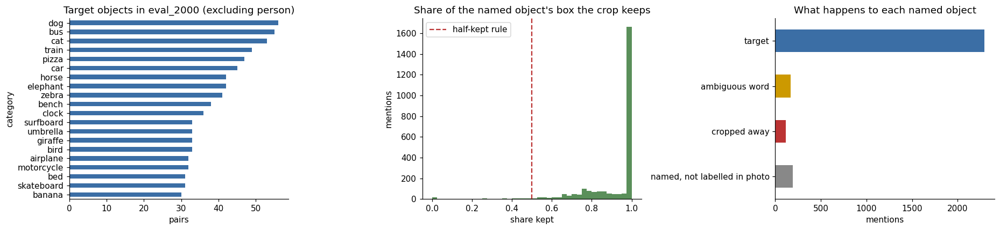

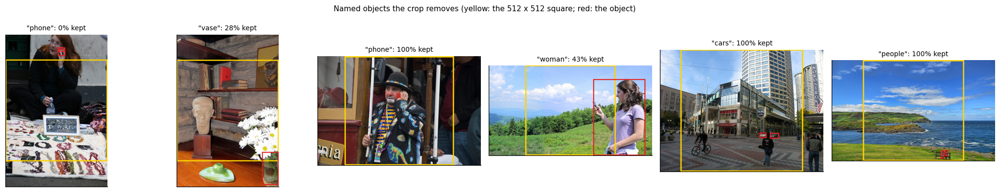

In [12]:
gt = GT["eval_2000"]
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
gt[gt.target & (gt.category != "person")].category.value_counts().head(20)[::-1].plot.barh(ax=ax[0], color="#3b6ea5")
ax[0].set(title="Target objects in eval_2000 (excluding person)", xlabel="pairs")
ax[1].hist(gt[gt.in_photo].box_fraction_kept, bins=40, color="#5a8f5a")
ax[1].axvline(CFG.min_box_kept, color="#b33", ls="--", label="half-kept rule")
ax[1].set(title="Share of the named object's box the crop keeps", xlabel="share kept", ylabel="mentions"); ax[1].legend()
outcome = pd.Series({"target": int(gt.target.sum()),
                     "ambiguous word": int((gt.ambiguous & gt.in_photo).sum()),
                     "cropped away": int((gt.in_photo & ~gt.survives_crop & ~gt.ambiguous).sum()),
                     "named, not labelled in photo": int((~gt.in_photo).sum())})
outcome[::-1].plot.barh(ax=ax[2], color=["#888", "#b33", "#c90", "#3b6ea5"])
ax[2].set(title="What happens to each named object", xlabel="mentions")
plt.tight_layout(); savefig("04_groundtruth_overview"); plt.show()

lost = gt[gt.in_photo & ~gt.survives_crop & ~gt.ambiguous].drop_duplicates("image_id").head(6)
if len(lost):
    fig, ax = plt.subplots(1, len(lost), figsize=(3.2 * len(lost), 3.6), squeeze=False)
    for a, r in zip(ax[0], lost.itertuples()):
        w, h = SIZES[r.image_id]
        img = Image.open(IMAGES_DIR / names[r.image_id]).convert("RGB")
        dr = ImageDraw.Draw(img)
        dr.rectangle(crop_box(w, h), outline=(255, 210, 0), width=5)
        for x, y, bw, bh in OBJECTS[r.image_id][r.category]:
            dr.rectangle([x, y, x + bw, y + bh], outline=(230, 30, 30), width=4)
        a.imshow(img); a.set_xticks([]); a.set_yticks([])
        a.set_title(f"\"{r.words}\": {r.box_fraction_kept:.0%} kept", fontsize=9)
    plt.suptitle("Named objects the crop removes (yellow: the 512 x 512 square; red: the object)", fontsize=10)
    plt.tight_layout(); savefig("05_cropped_away_examples"); plt.show()

## 8. Stress prompts

200 templated prompts in five families of 40, built from COCO objects so the detectors can judge them, each stored with its expected answer:

* **word order**: 20 pairs that swap roles, "a dog chasing a cat" / "a cat chasing a dog"
* **counting**: "three cups"
* **colour binding**: "a red car and a blue bus"
* **spatial**: "a cat to the left of a dog"
* **three objects**: "a bench, an umbrella and a cake"

In [13]:
ANIMALS = ["dog", "cat", "horse", "cow", "sheep", "bird", "elephant", "giraffe", "zebra", "bear"]
THINGS = ["car", "bus", "truck", "bicycle", "boat", "chair", "bench", "umbrella", "clock", "vase",
          "cup", "bowl", "bottle", "book", "laptop", "suitcase", "backpack", "pizza", "cake", "apple"]
COLOURS = ["red", "blue", "green", "yellow", "black", "white", "purple", "orange"]
NUMBERS = {2: "two", 3: "three", 4: "four", 5: "five"}
PLURAL = {"bus": "buses", "sheep": "sheep", "bench": "benches"}
VERBS = ["chasing", "looking at", "standing next to", "following", "sitting behind"]
SPATIAL = [("to the left of", "left"), ("to the right of", "right"), ("on top of", "above"), ("below", "below")]
SCENES = ["in a park", "in a field", "on a grassy hill", "in a backyard", "on a dirt road"]


def article(w):
    return "an" if w[0] in "aeiou" else "a"


def build_stress(seed):
    rng, rows = random.Random(seed), []

    def add(family, prompt, objects, expected, pair_id=""):
        k = sum(r["family"] == family for r in rows)
        rows.append({"prompt_id": f"{family}_{k:02d}", "family": family, "prompt": prompt,
                     "objects": json.dumps(objects), "expected": json.dumps(expected), "pair_id": pair_id})

    def count(f):
        return sum(r["family"] == f for r in rows)

    pairs = set()
    while len(pairs) < 20:
        a, b = rng.sample(ANIMALS, 2)
        pairs.add((a, b, rng.choice(VERBS), rng.choice(SCENES)))
    for k, (a, b, v, s) in enumerate(sorted(pairs)):
        for x, y in ((a, b), (b, a)):
            add("word_order", f"{article(x)} {x} {v} {article(y)} {y} {s}", [x, y],
                {"subject": x, "object": y, "verb": v}, f"wo{k:02d}")
    seen = set()
    while count("counting") < 40:
        o, n = rng.choice(ANIMALS + THINGS), rng.choice(list(NUMBERS))
        if (o, n) not in seen:
            seen.add((o, n))
            add("counting", f"{NUMBERS[n]} {PLURAL.get(o, o + 's')}", [o], {"count": {o: n}})
    seen = set()
    while count("colour_binding") < 40:
        a, b = rng.sample(THINGS, 2); ca, cb = rng.sample(COLOURS, 2)
        if (a, b, ca, cb) not in seen:
            seen.add((a, b, ca, cb))
            add("colour_binding", f"{article(ca)} {ca} {a} and {article(cb)} {cb} {b}", [a, b], {"colour": {a: ca, b: cb}})
    seen = set()
    while count("spatial") < 40:
        a, b = rng.sample(ANIMALS + THINGS, 2); phrase, rel = rng.choice(SPATIAL)
        if (a, b, rel) not in seen:
            seen.add((a, b, rel))
            add("spatial", f"{article(a)} {a} {phrase} {article(b)} {b}", [a, b], {"relation": rel, "first": a, "second": b})
    seen = set()
    while count("multi_object") < 40:
        objs = tuple(sorted(rng.sample(ANIMALS + THINGS, 3)))
        if objs not in seen:
            seen.add(objs)
            a, b, c = rng.sample(objs, 3)
            add("multi_object", f"{article(a)} {a}, {article(b)} {b} and {article(c)} {c}", [a, b, c], {"present": [a, b, c]})
    return pd.DataFrame(rows)


stress = build_stress(CFG.seed_stress)
assert len(stress) == 200 and stress.prompt.is_unique
assert stress.family.value_counts().eq(40).all()
for pid, g in stress[stress.family == "word_order"].groupby("pair_id"):
    a, b = g.prompt.tolist()
    assert sorted(a.split()) == sorted(b.split()) and a != b     # same words, different sentence
stress.to_csv(RESULTS / "stress_prompts.csv", index=False, lineterminator="\n")
stress.groupby("family").head(2)[["prompt_id", "prompt", "expected"]]

,prompt_id,prompt,expected
0,word_order_00,a bear following a sheep on a grassy hill,"{""subject"": ""bear"", ""object"": ""sheep"", ""verb"":..."
1,word_order_01,a sheep following a bear on a grassy hill,"{""subject"": ""sheep"", ""object"": ""bear"", ""verb"":..."
40,counting_00,four boats,"{""count"": {""boat"": 4}}"
41,counting_01,three zebras,"{""count"": {""zebra"": 3}}"
80,colour_binding_00,a yellow book and a white truck,"{""colour"": {""book"": ""yellow"", ""truck"": ""white""}}"
81,colour_binding_01,a green bicycle and a white vase,"{""colour"": {""bicycle"": ""green"", ""vase"": ""white""}}"
120,spatial_00,a bowl to the left of a zebra,"{""relation"": ""left"", ""first"": ""bowl"", ""second""..."
121,spatial_01,a car to the right of a boat,"{""relation"": ""right"", ""first"": ""car"", ""second""..."
160,multi_object_00,"a horse, a bus and a bottle","{""present"": [""horse"", ""bus"", ""bottle""]}"
161,multi_object_01,"a giraffe, a dog and a chair","{""present"": [""giraffe"", ""dog"", ""chair""]}"


## 9. Words CLIP splits into several tokens

CLIP's tokenizer breaks rarer words into pieces and marks the last piece with `</w>`; "frisbee" can become two pieces. Any per-word analysis of attention has to merge the pieces back into one word, otherwise a split word gets one timeline per piece. This counts how often that happens on the test captions, and which split words name target objects.

In [14]:
from transformers import CLIPTokenizer

tokenizer = CLIPTokenizer.from_pretrained(CFG.clip_id)


def sentence_words(prompt):
    # the prompt's words with their token positions; pieces are grouped on the '</w>' marker
    ids = tokenizer(prompt, padding="max_length", max_length=77, truncation=True)["input_ids"]
    words, cur, slots = [], "", []
    for i, tid in enumerate(ids):
        if tid == tokenizer.bos_token_id:
            continue
        if tid == tokenizer.eos_token_id:
            break
        piece = tokenizer.convert_ids_to_tokens(tid)
        cur += piece.replace("</w>", ""); slots.append(i)
        if piece.endswith("</w>"):
            words.append({"text": cur, "slots": slots}); cur, slots = "", []
    if slots:
        words.append({"text": cur, "slots": slots})
    return words


token_lengths = [len(tokenizer(c)["input_ids"]) for c in ev.caption]
split_counter, n_split_caps = Counter(), 0
for c in ev.caption:
    multi = [w["text"] for w in sentence_words(c) if w["text"].isalpha() and w["text"] not in STOPWORDS and len(w["slots"]) > 1]
    n_split_caps += bool(multi)
    split_counter.update(multi)
target_words = set(gt[gt.target].words.str.split().str[-1])
token_info = {"captions": len(ev), "over_77_tokens": int(sum(n > 77 for n in token_lengths)),
              "median_tokens": float(np.median(token_lengths)), "max_tokens": int(max(token_lengths)),
              "captions_with_a_split_word": n_split_caps,
              "most_common_split_words": split_counter.most_common(25),
              "split_words_that_name_targets": sorted(set(split_counter) & target_words)}
json.dump(token_info, open(RESULTS / "split_words.json", "w"), indent=2)
print(json.dumps(token_info, indent=2))
print("example:", [(w["text"], w["slots"]) for w in sentence_words("A man throwing a frisbee to a dog")])

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

{
  "captions": 2000,
  "over_77_tokens": 0,
  "median_tokens": 13.0,
  "max_tokens": 36,
  "captions_with_a_split_word": 379,
  "most_common_split_words": [
    [
      "computer",
      34
    ],
    [
      "surfboard",
      26
    ],
    [
      "zebras",
      22
    ],
    [
      "hydrant",
      18
    ],
    [
      "giraffes",
      12
    ],
    [
      "racquet",
      10
    ],
    [
      "skateboarder",
      8
    ],
    [
      "skiers",
      6
    ],
    [
      "computers",
      5
    ],
    [
      "wooded",
      4
    ],
    [
      "skateboarders",
      3
    ],
    [
      "vases",
      3
    ],
    [
      "cluttered",
      3
    ],
    [
      "crosswalk",
      3
    ],
    [
      "urinals",
      3
    ],
    [
      "surfboards",
      3
    ],
    [
      "jockeys",
      3
    ],
    [
      "garnish",
      2
    ],
    [
      "tablecloth",
      2
    ],
    [
      "stoplight",
      2
    ],
    [
      "bookcase",
      2
    ],
    [
      "

## 10. Text → embedding

Stable Diffusion never reads words. Its CLIP ViT-L/14 text transformer turns each caption into a **77 × 768 matrix**, one 768-number vector per token position (start token, the caption's pieces, end token, then padding up to 77), and the UNet reads that matrix through cross-attention at every denoising step.

This section builds that step ourselves, with the exact tokenizer and text encoder Stable Diffusion 1.5 ships with, and checks it three ways:

1. **Encode and cache** all 2,000 test captions once (plus the empty prompt, which classifier-free guidance runs against). Captions are encoded one at a time, as the pipeline does: half-precision GPU arithmetic gives slightly different numbers in large batches, and 30 denoising steps amplify the difference into visibly different images.
2. **Look inside** one caption's matrix.
3. **Do the embeddings mean anything?** CLIP's matching image encoder ranks the 2,000 test photos for every caption; the correct photo should come near the top far more often than chance (1 in 2,000).

Section 11 then closes the loop: an image generated from the cached matrix must match the image Stable Diffusion makes from the raw text.

In [15]:
import torch
import torch.nn.functional as F
from transformers import CLIPModel, CLIPProcessor, CLIPTextModel

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
assert DEVICE == "cuda", "From here on the notebook needs a GPU (Colab: Runtime -> Change runtime type -> T4 GPU)"
print(torch.__version__, torch.cuda.get_device_name(0))

# the exact tokenizer and text encoder Stable Diffusion 1.5 reads its prompts through
sd_tokenizer = CLIPTokenizer.from_pretrained(CFG.sd_id, subfolder="tokenizer")
text_encoder = CLIPTextModel.from_pretrained(CFG.sd_id, subfolder="text_encoder", torch_dtype=DTYPE).to(DEVICE).eval()
print(f"text encoder: {sum(p.numel() for p in text_encoder.parameters()) / 1e6:.0f}M parameters, "
      f"{text_encoder.config.num_hidden_layers} layers, width {text_encoder.config.hidden_size}")
CACHE = DATA / "cache"
CACHE.mkdir(exist_ok=True)


@torch.no_grad()
def encode(text):
    # one caption -> (77, 768): padded to 77, no attention mask, one prompt at a time, as the pipeline does
    ids = sd_tokenizer([text], padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids
    return text_encoder(ids.to(DEVICE))[0][0]


def build_cache(captions, name):
    path = CACHE / f"{name}_states_f16.npy"
    if path.exists() and np.load(path, mmap_mode="r").shape[0] == len(captions):
        return np.load(path, mmap_mode="r")
    arr = np.lib.format.open_memmap(path, mode="w+", dtype=np.float16, shape=(len(captions), 77, 768))
    for i, c in enumerate(tqdm(captions, desc=f"encode {name}")):
        arr[i] = encode(c).cpu().numpy()
    arr.flush()
    del arr
    return np.load(path, mmap_mode="r")


t0 = time.perf_counter()
STATES = build_cache(ev.caption.tolist(), "eval_2000")
NULL = encode("").cpu().numpy().astype(np.float16)
np.save(CACHE / "null_prompt_states_f16.npy", NULL)
ROW = {ci: i for i, ci in enumerate(ev.caption_idx)}           # caption_idx -> row of the cache
encode_seconds = round(time.perf_counter() - t0, 1)

# the cache must give back exactly what a fresh encoding gives
fresh = encode(ev.caption.iloc[123]).cpu().numpy().astype(np.float16)
assert np.array_equal(fresh, np.asarray(STATES[123])), "cache does not match a fresh encoding"
print(f"cached {STATES.shape} float16 ({STATES.nbytes / 1e6:.0f} MB) in {encode_seconds} s, "
      f"plus the empty prompt {NULL.shape}; cache == fresh encoding: OK")

2.11.0+cu130 Tesla T4


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

text encoder: 123M parameters, 12 layers, width 768


encode eval_2000:   0%|          | 0/2000 [00:00<?, ?it/s]

cached (2000, 77, 768) float16 (237 MB) in 18.0 s, plus the empty prompt (77, 768); cache == fresh encoding: OK


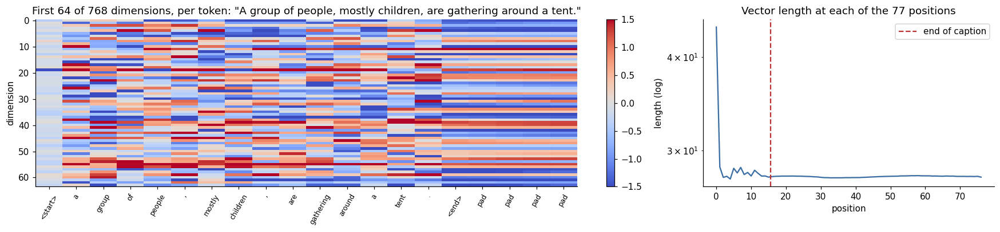

16 real tokens, 61 padding positions. The start token's vector is 2x longer than a word's, and the padding positions are not zero: with no attention mask they carry a summary of the caption, which the UNet also reads.


In [16]:
# what one caption's 77 x 768 matrix looks like
cap0 = ev.caption.iloc[0]
ids0 = sd_tokenizer(cap0)["input_ids"]                          # with start and end tokens, no padding
labels = ["<start>"] + [sd_tokenizer.convert_ids_to_tokens(t).replace("</w>", "") for t in ids0[1:-1]] + ["<end>"]
n_show = len(ids0) + 4
labels += ["pad"] * (n_show - len(labels))
s0 = np.asarray(STATES[0], dtype=np.float32)
norms = np.linalg.norm(s0, axis=1)

fig, ax = plt.subplots(1, 2, figsize=(16, 3.8), gridspec_kw={"width_ratios": [2, 1]})
im = ax[0].imshow(s0[:n_show, :64].T, aspect="auto", cmap="coolwarm", vmin=-1.5, vmax=1.5)
ax[0].set_xticks(range(n_show)); ax[0].set_xticklabels(labels, rotation=60, fontsize=8)
ax[0].set(title=f"First 64 of 768 dimensions, per token: \"{cap0}\"", ylabel="dimension")
plt.colorbar(im, ax=ax[0], fraction=0.02)
ax[1].semilogy(norms, color="#3b6ea5")
ax[1].axvline(len(ids0) - 0.5, color="#b33", ls="--", label="end of caption")
ax[1].set(title="Vector length at each of the 77 positions", xlabel="position", ylabel="length (log)")
ax[1].legend()
plt.tight_layout(); savefig("09_embedding_matrix"); plt.show()
print(f"{len(ids0)} real tokens, {77 - len(ids0)} padding positions. The start token's vector is "
      f"{norms[0] / np.median(norms[1:len(ids0)]):.0f}x longer than a word's, and the padding positions are not zero: "
      f"with no attention mask they carry a summary of the caption, which the UNet also reads.")

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

Stable Diffusion's text encoder vs CLIP ViT-L/14's text tower: max difference 0.0000
{
  "recall@1": 0.4675,
  "recall@5": 0.733,
  "recall@10": 0.84,
  "median_rank": 2.0,
  "chance_recall@1": 0.0005,
  "n": 2000
}


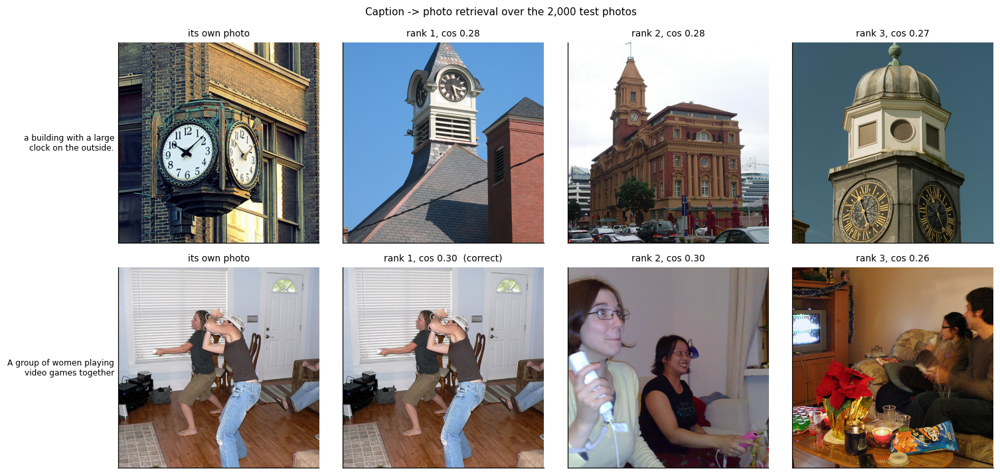

In [17]:
# do the embeddings mean anything? caption -> photo retrieval over the 2,000 test pairs
clip_model = CLIPModel.from_pretrained(CFG.clip_id, torch_dtype=DTYPE).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CFG.clip_id)


@torch.no_grad()
def clip_features(paths, texts, batch=32):
    # CLIP ViT-L/14 image and caption vectors, both length 1 (cosine = dot product)
    fi, ft = [], []
    for i in range(0, len(paths), batch):
        ims = [Image.open(p).convert("RGB") for p in paths[i:i + batch]]
        px = clip_proc.image_processor(images=ims, return_tensors="pt")["pixel_values"].to(DEVICE, DTYPE)
        v = clip_model.visual_projection(clip_model.vision_model(pixel_values=px).pooler_output)
        tok = clip_proc.tokenizer(list(texts[i:i + batch]), padding="max_length", max_length=77,
                                  truncation=True, return_tensors="pt").to(DEVICE)
        t = clip_model.text_projection(clip_model.text_model(input_ids=tok.input_ids).pooler_output)
        fi.append(F.normalize(v.float(), dim=-1).cpu().numpy())
        ft.append(F.normalize(t.float(), dim=-1).cpu().numpy())
    return np.concatenate(fi), np.concatenate(ft)


# the CLIP used for scoring has the same text transformer Stable Diffusion reads
with torch.no_grad():
    ids = sd_tokenizer([cap0], padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to(DEVICE)
    same_encoder_diff = float((clip_model.text_model(input_ids=ids).last_hidden_state[0] - encode(cap0)).abs().max())
print(f"Stable Diffusion's text encoder vs CLIP ViT-L/14's text tower: max difference {same_encoder_diff:.4f}")

real_A = [png_path(names[i]) for i in ev.image_id]
img_f, txt_f = clip_features(real_A, ev.caption.tolist())
sims = txt_f @ img_f.T                                          # captions x photos
ranks = (sims > np.diag(sims)[:, None]).sum(1)                  # photos scoring above the right one
retrieval = {f"recall@{k}": float((ranks < k).mean()) for k in (1, 5, 10)}
retrieval.update({"median_rank": float(np.median(ranks) + 1), "chance_recall@1": 1 / len(ev), "n": len(ev)})
json.dump(retrieval, open(RESULTS / "retrieval.json", "w"), indent=2)
print(json.dumps(retrieval, indent=2))

fig, ax = plt.subplots(2, 4, figsize=(14, 6.6))
for row, i in enumerate([3, 11]):
    top = np.argsort(-sims[i])[:3]
    ax[row, 0].imshow(Image.open(real_A[i])); ax[row, 0].set_title("its own photo", fontsize=9)
    ax[row, 0].set_ylabel(textwrap.fill(ev.caption.iloc[i], 28), fontsize=8, rotation=0, ha="right", va="center")
    for k, j in enumerate(top):
        ax[row, k + 1].imshow(Image.open(real_A[j]))
        ax[row, k + 1].set_title(f"rank {k + 1}, cos {sims[i, j]:.2f}" + ("  (correct)" if j == i else ""), fontsize=9)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
plt.suptitle("Caption -> photo retrieval over the 2,000 test photos", fontsize=10)
plt.tight_layout(); savefig("10_retrieval_examples"); plt.show()

## 11. Stable Diffusion: first samples

Stable Diffusion 1.5, frozen, reading prompts through the text encoder from Section 10, with its defaults: PNDM scheduler, 30 steps, classifier-free guidance 7.5.

1. **Parity check.** One caption, one seed, painted twice: once from the raw text, once from our cached 77 × 768 states. If the pipeline we built is the one driving the model, the two images are identical.
2. **Sample runs.** Five test captions, picked with a fixed seed among photos showing at least two kinds of object (so the captions are not trivial), three seeds each, generated **from the cached embeddings** and shown beside the real photo.

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

scheduler: PNDMScheduler


/tmp/ipykernel_457/4169371921.py:23: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  pe = torch.from_numpy(np.asarray(states)).to(DEVICE, DTYPE).unsqueeze(0)


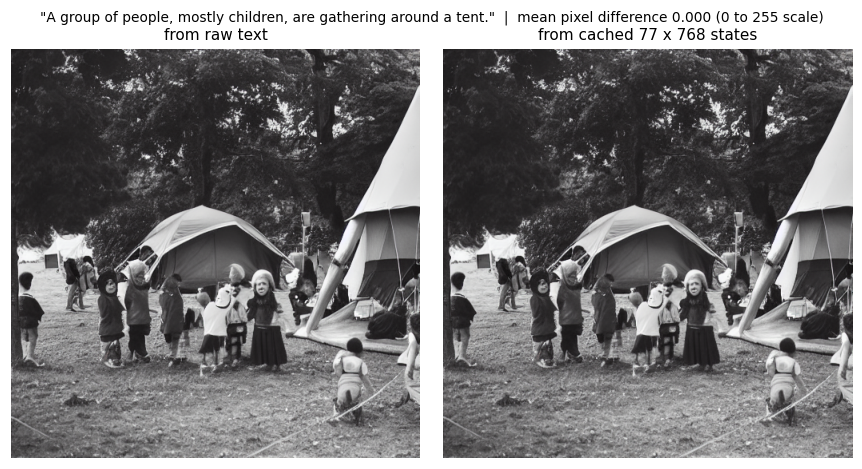

one image: 4.7 s; mean pixel difference text vs cache: 0.000


In [18]:
from diffusers import StableDiffusionPipeline

# the pipeline gets the text encoder from Section 10, so there is exactly one copy of it
pipe = StableDiffusionPipeline.from_pretrained(CFG.sd_id, text_encoder=text_encoder, tokenizer=sd_tokenizer,
                                               torch_dtype=DTYPE).to(DEVICE)
pipe.set_progress_bar_config(disable=True)
print("scheduler:", type(pipe.scheduler).__name__)


@torch.no_grad()
def paint(prompt, seed, steps=CFG.steps, guidance=CFG.guidance):
    g = torch.Generator(DEVICE).manual_seed(int(seed))
    torch.cuda.synchronize(); t0 = time.perf_counter()
    out = pipe(prompt, num_inference_steps=steps, guidance_scale=guidance, generator=g)
    torch.cuda.synchronize()
    flags = getattr(out, "nsfw_content_detected", None)
    return out.images[0], bool(flags[0]) if flags is not None else False, time.perf_counter() - t0


@torch.no_grad()
def paint_embeds(states, seed, steps=CFG.steps, guidance=CFG.guidance):
    # the same painting, driven by our cached 77 x 768 states instead of raw text
    pe = torch.from_numpy(np.asarray(states)).to(DEVICE, DTYPE).unsqueeze(0)
    ne = torch.from_numpy(NULL).to(DEVICE, DTYPE).unsqueeze(0)
    g = torch.Generator(DEVICE).manual_seed(int(seed))
    torch.cuda.synchronize(); t0 = time.perf_counter()
    out = pipe(prompt_embeds=pe, negative_prompt_embeds=ne, num_inference_steps=steps, guidance_scale=guidance, generator=g)
    torch.cuda.synchronize()
    flags = getattr(out, "nsfw_content_detected", None)
    return out.images[0], bool(flags[0]) if flags is not None else False, time.perf_counter() - t0


paint("a cat sitting on a wooden bench in a park", 0, steps=5)            # warm-up, untimed

# parity: the image from our cached embeddings must equal the image from the raw text
cap = ev.caption.iloc[0]
from_text, _, t_text = paint(cap, 123)
from_cache, _, t_cache = paint_embeds(STATES[ROW[ev.caption_idx.iloc[0]]], 123)
parity_diff = float(np.abs(np.asarray(from_text, np.float32) - np.asarray(from_cache, np.float32)).mean())
fig, ax = plt.subplots(1, 2, figsize=(8, 4.3))
for a, im, t in zip(ax, (from_text, from_cache), ("from raw text", "from cached 77 x 768 states")):
    a.imshow(im); a.set_title(t, fontsize=10); a.axis("off")
plt.suptitle(f"\"{cap}\"  |  mean pixel difference {parity_diff:.3f} (0 to 255 scale)", fontsize=9)
plt.tight_layout(); savefig("11_parity_text_vs_cache"); plt.show()
print(f"one image: {t_text:.1f} s; mean pixel difference text vs cache: {parity_diff:.3f}")
if parity_diff > 0.5:
    print("WARNING: images differ. Check that captions were encoded one at a time with no attention mask.")

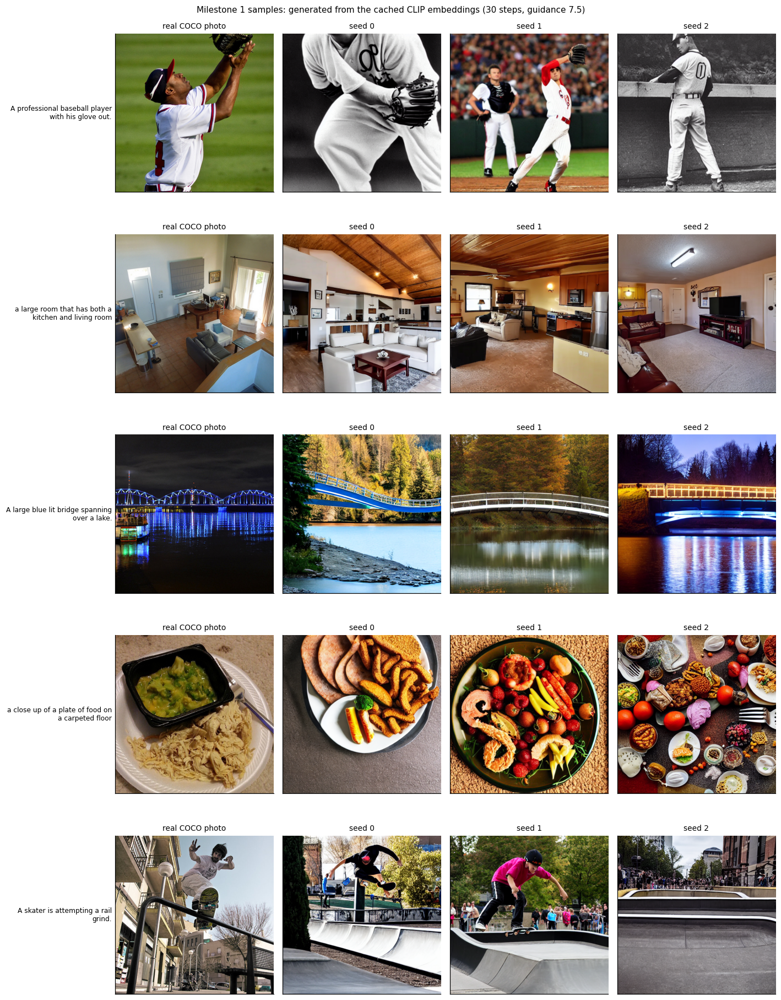

In [19]:
# sample prompt -> image runs next to the real photos
rng = random.Random(7)
multi = ev[ev.image_id.map(manifest.set_index("image_id").categories.map(len)) >= 2]
samples = multi.iloc[sorted(rng.sample(range(len(multi)), 5))]
seeds = list(CFG.sample_seeds)
fig, ax = plt.subplots(len(samples), 4, figsize=(13, 3.4 * len(samples)))
sample_dir = SAMPLES
sample_seconds = []
for i, r in enumerate(samples.itertuples()):
    ax[i, 0].imshow(Image.open(png_path(names[r.image_id]))); ax[i, 0].set_title("real COCO photo", fontsize=9)
    ax[i, 0].set_ylabel(textwrap.fill(r.caption, 32), fontsize=8, rotation=0, ha="right", va="center")
    for j, s in enumerate(seeds):
        im, flag, dt = paint_embeds(STATES[ROW[r.caption_idx]], s)     # driven by our own embeddings
        im.save(sample_dir / f"{r.caption_idx}_s{s}.png")
        sample_seconds.append(dt)
        ax[i, j + 1].imshow(im); ax[i, j + 1].set_title(f"seed {s}" + ("  [flagged]" if flag else ""), fontsize=9)
for a in ax.flat:
    a.set_xticks([]); a.set_yticks([])
plt.suptitle("Milestone 1 samples: generated from the cached CLIP embeddings (30 steps, guidance 7.5)", fontsize=10)
plt.tight_layout(); savefig("06_m1_samples"); plt.show()

In [20]:
# every sample with its caption, seed and settings, so each image can be reproduced
records = [{"file": f"{r.caption_idx}_s{s_}.png", "image_id": int(r.image_id), "caption_idx": int(r.caption_idx),
            "caption": r.caption, "seed": s_, "steps": CFG.steps, "guidance": CFG.guidance, "scheduler": "PNDM",
            "conditioning": "cached CLIP ViT-L/14 states"} for r in samples.itertuples() for s_ in seeds]
pd.DataFrame(records).to_csv(SAMPLES / "samples.csv", index=False)
print(f"{len(records)} samples, {np.mean(sample_seconds):.1f} s each, saved to {SAMPLES}")

15 samples, 5.1 s each, saved to /content/drive/MyDrive/w2w_praniti/samples


## 12. Milestone 1 summary

Every Milestone 1 number in one file, `results/milestone1_summary.json`, followed by the list of everything saved.

In [21]:
# Milestone 1 summary
m1 = {
    "dataset": "MS-COCO 2017 val", "cleaning": cleaning_log,
    "preprocessing": {"size": CFG.image_size, "method": "RGB, center crop, Lanczos resize, PNG",
                      "converted_to_rgb": int((pre.mode_in != "RGB").sum()),
                      "mean_crop_kept": round(float(pre.crop_fraction_kept.mean()), 4),
                      "reference_eligible": int(pre.reference_eligible.sum())},
    "splits": {"eval_2000": len(ev), "dev_500": len(dev), "real_ref_b_2000": len(refb)},
    "text_to_embedding": {"encoder": f"{CFG.sd_id} text_encoder (CLIP ViT-L/14)", "shape": list(STATES.shape[1:]),
                          "captions_cached": int(STATES.shape[0]), "seconds": encode_seconds,
                          "same_as_clip_text_tower_max_diff": same_encoder_diff,
                          "retrieval": retrieval, "image_from_text_vs_cache_mean_pixel_diff": parity_diff},
    "data_checks": {"exif_tagged": checks["exif_orientation"]["tagged_images"],
                    "near_duplicate_pairs": checks["near_duplicates"]["pairs"],
                    "caption_quirks": {k: v for k, v in checks["caption_quirks_kept_on_purpose"].items()
                                       if k != "repeated_word_examples"}},
    "object_labels_eval_2000": {k: v for k, v in gt_info["eval_2000"].items() if k != "top_unmapped_words"},
    "stress_prompts": stress.family.value_counts().to_dict(),
    "tokens": {k: v for k, v in token_info.items() if k != "most_common_split_words"},
    "samples": {"captions": samples.caption.tolist(), "seeds": seeds, "steps": CFG.steps, "guidance": CFG.guidance,
                "seconds_per_image": round(float(np.mean(sample_seconds)), 2), "folder": str(sample_dir)},
    "environment": {"python": platform.python_version(), "torch": torch.__version__,
                    "gpu": torch.cuda.get_device_name(0)},
}
import diffusers, transformers
m1["environment"].update(diffusers=diffusers.__version__, transformers=transformers.__version__)
json.dump(m1, open(RESULTS / "milestone1_summary.json", "w"), indent=2, default=str)
print(json.dumps(m1, indent=2, default=str))

print("\nSaved:")
for p in sorted(RESULTS_ROOT.rglob("*")):
    if p.is_file():
        print("  ", p.relative_to(RESULTS_ROOT))


{
  "dataset": "MS-COCO 2017 val",
  "cleaning": {
    "captions_whitespace_fixed": 3832,
    "captions_duplicate_dropped": 10,
    "images": 5000,
    "captions_raw": 25014,
    "captions_kept": 25004
  },
  "preprocessing": {
    "size": 512,
    "method": "RGB, center crop, Lanczos resize, PNG",
    "converted_to_rgb": 10,
    "mean_crop_kept": 0.716,
    "reference_eligible": 4958
  },
  "splits": {
    "eval_2000": 2000,
    "dev_500": 500,
    "real_ref_b_2000": 2000
  },
  "text_to_embedding": {
    "encoder": "stable-diffusion-v1-5/stable-diffusion-v1-5 text_encoder (CLIP ViT-L/14)",
    "shape": [
      77,
      768
    ],
    "captions_cached": 2000,
    "seconds": 18.0,
    "same_as_clip_text_tower_max_diff": 0.0,
    "retrieval": {
      "recall@1": 0.4675,
      "recall@5": 0.733,
      "recall@10": 0.84,
      "median_rank": 2.0,
      "chance_recall@1": 0.0005,
      "n": 2000
    },
    "image_from_text_vs_cache_mean_pixel_diff": 0.0
  },
  "data_checks": {
    "exif_t

# Part 2 · Text encoders compared without training

## 13. Why compare text encoders

Stable Diffusion 1.5 reads its prompts through CLIP's text transformer. The project also considers other Transformer text encoders (BERT, GPT-2), which would need a trained connector before Stable Diffusion could use them. Before spending GPU hours on that, this notebook measures what each encoder's embeddings **already** capture, on the same 2,000 test captions. Nothing is trained.

| Question | Test |
|---|---|
| How similar are the encoders' views of the same captions? | Linear CKA between every pair of encoders |
| Do paraphrases land close together? | Caption → caption retrieval: find another human caption of the same photo among 2,000 |
| Do captions about the same kind of scene cluster? | Nearest-neighbour accuracy on the photo's main object type, plus t-SNE maps |
| Does the encoder notice **word order** and **which colour goes with which object**? | Triplets of sentences with exactly the same words: is a same-meaning rewording closer than a meaning-changing swap? |

**Encoders:** CLIP ViT-L/14 (Stable Diffusion's own text encoder), BERT-base, T5-base (encoder) and GPT-2. All four are 768 numbers wide, so differences come from what they learned, not from their size. A **TF-IDF word-count baseline**, which knows only which words appear, marks how far word overlap alone gets.

**Why this matters.** CLIP was trained to match text with images; BERT, T5 and GPT-2 were trained on text alone. If they organise captions very differently from CLIP, a connector has a lot to learn; if one of them captures something CLIP misses (such as word order), it has something to offer.

Part 2 reuses Part 1's 2,000 test captions, its stress prompts, and the Stable Diffusion text encoder already loaded in Section 10. It adds about 10 minutes.

## 14. Paraphrases, scene labels and triplets

* **Paraphrase**: for each test caption, another human caption of the same photo (Part 1's caption table has up to five per photo).
* **Scene label**: the COCO supercategory of the photo's largest labelled object (animal, vehicle, food, …), from the photo's boxes, not the caption.
* **Triplets** that all use exactly the same words, built from the Section 8 stress prompts:

| | Original | Same meaning, reworded | Meaning changed |
|---|---|---|---|
| **Word order** (20) | a bear following a sheep on a grassy hill | on a grassy hill a bear following a sheep | a sheep following a bear on a grassy hill |
| **Colour binding** (40) | a yellow book and a white truck | a white truck and a yellow book | a white book and a yellow truck |

A good encoder puts the same-meaning rewording closer to the original than the meaning-changing swap; one that only registers which words appear scores 50% (chance).

In [22]:
TE = dict(encoders={"CLIP ViT-L/14": "sd_text_encoder", "BERT-base": "google-bert/bert-base-uncased",
                    "T5-base": "google-t5/t5-base", "GPT-2": "openai-community/gpt2"}, knn_k=10)
TE_OUT = RESULTS / "text_encoders"
TE_OUT.mkdir(exist_ok=True)

other = caps[caps.image_id.isin(ev.image_id) & ~caps.caption_idx.isin(ev.caption_idx)]
para = other.groupby("image_id").first().reindex(ev.image_id).caption.tolist()
assert all(isinstance(p, str) for p in para) and len(para) == len(ev)

cat_super = {c["id"]: c["supercategory"] for c in inst_json["categories"]}
largest = {}
for a in inst_json["annotations"]:
    if a["image_id"] not in largest or a["area"] > largest[a["image_id"]][0]:
        largest[a["image_id"]] = (a["area"], cat_super[a["category_id"]])
scene = np.array([largest.get(i, (0, "none"))[1] for i in ev.image_id])
print("scene types:", pd.Series(scene).value_counts().to_dict())


def stress_triplets(seed):
    # replays the Section 8 random draws, for the word-order and colour-binding families
    rng = random.Random(seed)
    pairs = set()
    while len(pairs) < 20:
        a, b = rng.sample(ANIMALS, 2)
        pairs.add((a, b, rng.choice(VERBS), rng.choice(SCENES)))
    order = [(f"{article(a)} {a} {v} {article(b)} {b} {s}", f"{s} {article(a)} {a} {v} {article(b)} {b}",
              f"{article(b)} {b} {v} {article(a)} {a} {s}") for a, b, v, s in sorted(pairs)]
    seen = set()
    while len(seen) < 40:                                         # the counting draws, replayed
        seen.add((rng.choice(ANIMALS + THINGS), rng.choice(list(NUMBERS))))
    colour, seen = [], set()
    while len(colour) < 40:
        a, b = rng.sample(THINGS, 2); ca, cb = rng.sample(COLOURS, 2)
        if (a, b, ca, cb) not in seen:
            seen.add((a, b, ca, cb))
            colour.append((f"{article(ca)} {ca} {a} and {article(cb)} {cb} {b}",
                           f"{article(cb)} {cb} {b} and {article(ca)} {ca} {a}",
                           f"{article(cb)} {cb} {a} and {article(ca)} {ca} {b}"))
    return order, colour


ORDER_TRIPLETS, COLOUR_TRIPLETS = stress_triplets(CFG.seed_stress)
assert [t[0] for t in ORDER_TRIPLETS] == stress[stress.family == "word_order"].prompt.tolist()[::2]
assert [t[0] for t in COLOUR_TRIPLETS] == stress[stress.family == "colour_binding"].prompt.tolist()
for x, same, changed in ORDER_TRIPLETS + COLOUR_TRIPLETS:
    assert sorted(x.split()) == sorted(same.split()) == sorted(changed.split()) and len({x, same, changed}) == 3
print(f"{len(ORDER_TRIPLETS)} word-order and {len(COLOUR_TRIPLETS)} colour triplets, matching the Section 8 stress prompts")
print(ORDER_TRIPLETS[0]); print(COLOUR_TRIPLETS[0])

scene types: {'person': 598, 'vehicle': 326, 'furniture': 268, 'animal': 267, 'outdoor': 108, 'indoor': 94, 'food': 89, 'appliance': 70, 'electronic': 52, 'kitchen': 41, 'accessory': 37, 'sports': 31, 'none': 19}
20 word-order and 40 colour triplets, matching the Section 8 stress prompts
('a bear following a sheep on a grassy hill', 'on a grassy hill a bear following a sheep', 'a sheep following a bear on a grassy hill')
('a yellow book and a white truck', 'a white truck and a yellow book', 'a white book and a yellow truck')


## 15. Embedding the captions with CLIP, BERT, T5 and GPT-2

For each encoder, each caption becomes:

* **token states**: one 768-number vector per token, the form a diffusion model reads through cross-attention;
* **a sentence vector**: the mean of the token states, leaving out padding and special tokens (start, end, `[CLS]`, `[SEP]`), the same rule for every encoder. For CLIP, its own sentence vector (the end-of-text token, which CLIP was trained to use) is reported as a fifth row, "CLIP (EOS)".

CLIP reads at most 77 tokens, so every encoder is cut at 77 for a like-for-like comparison (no test caption is that long).

CLIP here is the exact text encoder Stable Diffusion reads (loaded in Section 10), so its row describes the model's own view of the captions.

In [23]:
from collections import defaultdict
from transformers import AutoModel, AutoTokenizer, T5EncoderModel


def load_encoder(name, ref):
    if ref == "sd_text_encoder":                          # Stable Diffusion's own, already loaded in Section 10
        return sd_tokenizer, text_encoder
    if "t5" in ref:
        tok, model = AutoTokenizer.from_pretrained(ref), T5EncoderModel.from_pretrained(ref)
    else:
        tok, model = AutoTokenizer.from_pretrained(ref), AutoModel.from_pretrained(ref)
    if tok.pad_token is None:                              # GPT-2 has no padding token
        tok.pad_token = tok.eos_token
    return tok, model.to(DEVICE).eval()


@torch.no_grad()
def embed(tok, model, ref, texts, batch=64):
    sent, eos, n_tokens = [], [], []
    for i in range(0, len(texts), batch):
        enc = tok(list(texts[i:i + batch]), padding=True, truncation=True, max_length=77,
                  return_tensors="pt", return_special_tokens_mask=True)
        special = enc.pop("special_tokens_mask")
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        out = model(**enc)
        h = out.last_hidden_state.float()
        keep = (enc["attention_mask"].bool() & ~special.to(DEVICE).bool()).float().unsqueeze(-1)
        sent.append((h * keep).sum(1) / keep.sum(1).clamp(min=1))
        n_tokens += enc["attention_mask"].sum(1).tolist()
        if ref == "sd_text_encoder":
            eos.append(out.pooler_output.float())
    result = {"sent": torch.cat(sent).cpu().numpy(), "tokens": np.array(n_tokens)}
    if eos:
        result["eos"] = torch.cat(eos).cpu().numpy()
    return result


texts = {"captions": ev.caption.tolist(), "paraphrases": para}
for fam, trip in (("order", ORDER_TRIPLETS), ("colour", COLOUR_TRIPLETS)):
    for j, part in enumerate(("orig", "same", "changed")):
        texts[f"{fam}_{part}"] = [t[j] for t in trip]
EMB = defaultdict(dict)                    # EMB[representation][text set] -> (n, 768)
TOKENS = {}
t0 = time.perf_counter()
for name, ref in TE["encoders"].items():
    tok, model = load_encoder(name, ref)
    for key, tx in texts.items():
        r = embed(tok, model, ref, tx)
        EMB[name][key] = r["sent"]
        if "eos" in r:
            EMB["CLIP (EOS)"][key] = r["eos"]
        if key == "captions":
            TOKENS[name] = r["tokens"]
    if ref != "sd_text_encoder":
        del model; torch.cuda.empty_cache()
    print(f"{name:14s} done, width {EMB[name]['captions'].shape[1]}")
print(f"all encoders in {time.perf_counter() - t0:.0f} s")

CLIP ViT-L/14  done, width 768


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

... (16 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT-2          done, width 768
all encoders in 101 s


In [24]:
# the word-count baseline: knows which words appear, nothing about order or meaning
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(lowercase=True, token_pattern=r"[a-zA-Z]+").fit(caps.caption)
for key, tx in texts.items():
    EMB["TF-IDF words"][key] = tfidf.transform(tx).toarray().astype(np.float32)
REPS = ["CLIP ViT-L/14", "CLIP (EOS)", "BERT-base", "T5-base", "GPT-2", "TF-IDF words"]

tok_table = pd.DataFrame({n: {"median tokens": float(np.median(t)), "max tokens": int(t.max())} for n, t in TOKENS.items()}).T
print(tok_table)

               median tokens  max tokens
CLIP ViT-L/14           13.0        36.0
BERT-base               13.0        36.0
T5-base                 14.0        41.0
GPT-2                   11.0        34.0


## 16. How similar are the encoders? (linear CKA)

Linear CKA compares two sets of embeddings of the same 2,000 captions: 1 means one is a rotation and rescaling of the other (the same information, arranged differently), 0 means they share nothing linear. It is the standard way to compare representations of different models, and it ignores the scale and orientation that differ between encoders.

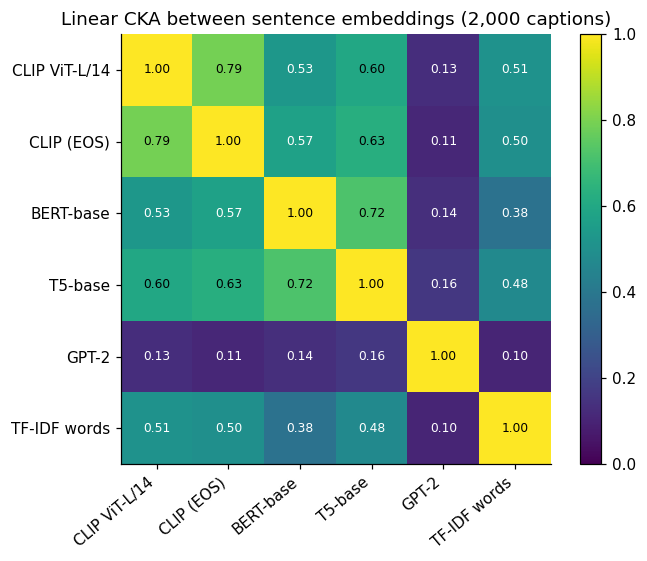

In [25]:
def linear_cka(x, y):
    x = x - x.mean(0); y = y - y.mean(0)
    hsic = np.linalg.norm(y.T @ x) ** 2
    return float(hsic / (np.linalg.norm(x.T @ x) * np.linalg.norm(y.T @ y)))


cka = pd.DataFrame([[linear_cka(EMB[a]["captions"], EMB[b]["captions"]) for b in REPS] for a in REPS], index=REPS, columns=REPS)
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(cka.values, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(REPS))); ax.set_xticklabels(REPS, rotation=40, ha="right")
ax.set_yticks(range(len(REPS))); ax.set_yticklabels(REPS)
for i in range(len(REPS)):
    for j in range(len(REPS)):
        ax.text(j, i, f"{cka.values[i, j]:.2f}", ha="center", va="center", color="white" if cka.values[i, j] < 0.6 else "black", fontsize=8)
plt.colorbar(im, fraction=0.046); ax.set_title("Linear CKA between sentence embeddings (2,000 captions)")
plt.tight_layout(); savefig("A1_cka"); plt.show()
cka.round(3).to_csv(TE_OUT / "A_cka.csv")

## 17. Do paraphrases land close together? (caption → caption retrieval)

Every test photo has other human captions. For each test caption, all 2,000 "other captions" are ranked by cosine similarity, and we check whether the one describing **the same photo** comes first. People describe the same photo with different words, so this rewards encoders that capture meaning rather than wording. The TF-IDF row shows how far word overlap alone gets.

,R@1,R@5,R@10,median rank
CLIP ViT-L/14,0.214,0.412,0.522,9.0
CLIP (EOS),0.340,0.578,0.693,3.0
BERT-base,0.130,0.277,0.350,29.0
T5-base,0.154,0.310,0.400,22.0
GPT-2,0.034,0.094,0.134,315.0
TF-IDF words,0.200,0.380,0.479,12.0


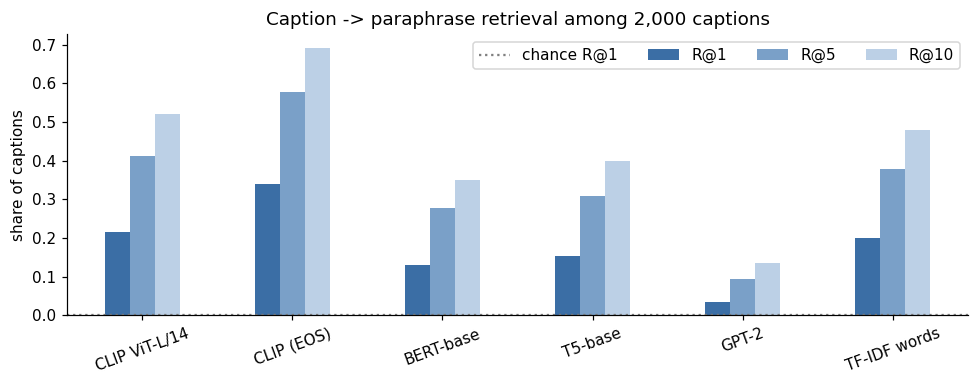

In [26]:
def l2n(x):
    return x / np.clip(np.linalg.norm(x, axis=1, keepdims=True), 1e-8, None)


def retrieval(q, g):
    sims = l2n(q) @ l2n(g).T
    ranks = (sims > np.diag(sims)[:, None]).sum(1)
    return {"R@1": float((ranks < 1).mean()), "R@5": float((ranks < 5).mean()),
            "R@10": float((ranks < 10).mean()), "median rank": float(np.median(ranks) + 1)}


ret = pd.DataFrame({r: retrieval(EMB[r]["captions"], EMB[r]["paraphrases"]) for r in REPS}).T
ret.to_csv(TE_OUT / "A_paraphrase_retrieval.csv")
display(ret.round(3))
ax = ret[["R@1", "R@5", "R@10"]].plot.bar(figsize=(9, 3.6), rot=20, color=["#3b6ea5", "#7aa0c8", "#bcd0e6"])
ax.axhline(1 / len(ev), color="gray", ls=":", label="chance R@1")
ax.set(title="Caption -> paraphrase retrieval among 2,000 captions", ylabel="share of captions"); ax.legend(ncol=4)
plt.tight_layout(); savefig("A2_paraphrase_retrieval"); plt.show()

## 18. Do captions about the same kind of scene cluster?

Each test caption is labelled with the COCO supercategory of the largest object in its photo (animal, vehicle, food, sports, furniture, …; the label comes from the photo's boxes, not from the caption). A caption is classified by a vote among its 10 nearest captions (leaving itself out). Higher accuracy means the embedding groups captions by what the scene contains. The t-SNE maps show the same thing as pictures.

,10-NN scene accuracy,majority_class
CLIP ViT-L/14,0.700,0.299
CLIP (EOS),0.745,0.299
BERT-base,0.658,0.299
T5-base,0.684,0.299
GPT-2,0.560,0.299
TF-IDF words,0.644,0.299


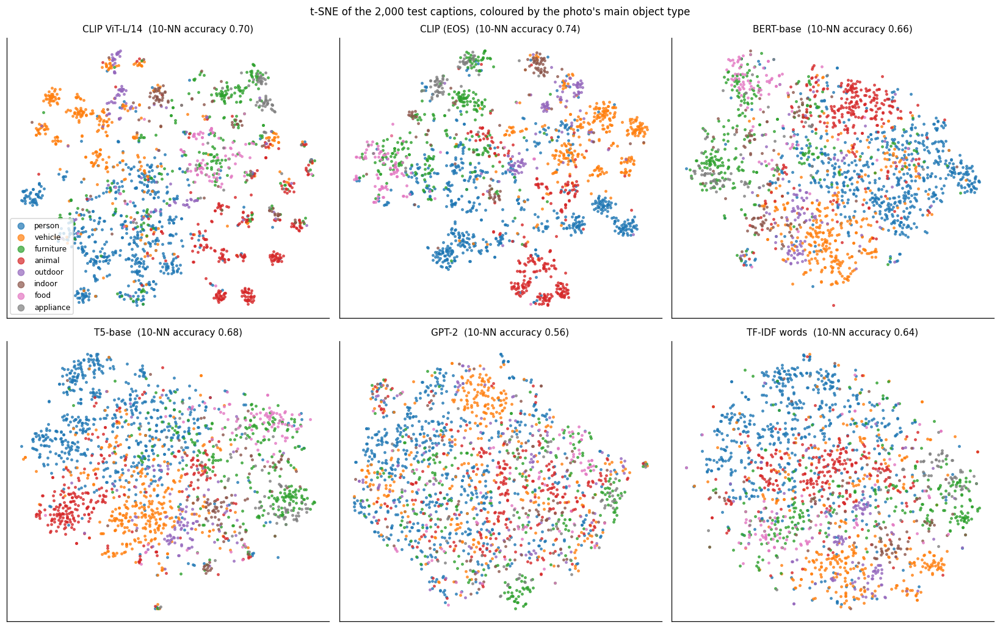

In [27]:
from sklearn.manifold import TSNE

labels = scene
majority = float(pd.Series(labels).value_counts(normalize=True).iloc[0])


def knn_accuracy(x, y, k=TE["knn_k"]):
    s = l2n(x) @ l2n(x).T
    np.fill_diagonal(s, -np.inf)
    nn = np.argsort(-s, axis=1)[:, :k]
    pred = [Counter(y[row]).most_common(1)[0][0] for row in nn]
    return float((np.array(pred) == y).mean())


knn = pd.Series({r: knn_accuracy(EMB[r]["captions"], labels) for r in REPS}, name="10-NN scene accuracy")
display(knn.round(3).to_frame().assign(majority_class=round(majority, 3)))
knn.to_csv(TE_OUT / "A_knn_scene.csv")

top = pd.Series(labels).value_counts().index[:8]
palette = dict(zip(top, plt.cm.tab10.colors))
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5))
for ax, r in zip(axes.flat, REPS):
    xy = TSNE(n_components=2, init="pca", perplexity=30, random_state=0).fit_transform(l2n(EMB[r]["captions"]))
    for lab in top:
        m = labels == lab
        ax.scatter(xy[m, 0], xy[m, 1], s=5, color=palette[lab], label=lab, alpha=0.7)
    ax.set_title(f"{r}  (10-NN accuracy {knn[r]:.2f})", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
axes.flat[0].legend(markerscale=3, fontsize=8, loc="best")
plt.suptitle("t-SNE of the 2,000 test captions, coloured by the photo's main object type", fontsize=11)
plt.tight_layout(); savefig("A3_tsne"); plt.show()

## 19. Word order and colour binding

For each triplet (Section 3), the encoder **passes** if the same-meaning rewording is closer (cosine) to the original than the meaning-changing swap. The score is the share of triplets passed: **50% is chance**, which is what an encoder that only counts words gets. The margin is the average of cos(original, same meaning) − cos(original, meaning changed): positive means the encoder leans the right way.

These use sentence vectors. A diffusion model reads every token state, not one vector, so this is a measure of what the encoder captures, not a direct prediction of the images.

,word order: pass rate,word order: margin,colour: pass rate,colour: margin,"word order: cos(orig, swapped)","colour: cos(orig, swapped)"
encoder,,,,,,
CLIP ViT-L/14,0.0,-0.140,0.000,-0.061,0.914,0.761
CLIP (EOS),0.0,-0.038,0.425,0.006,0.968,0.960
BERT-base,0.0,-0.031,0.000,-0.026,0.993,0.996
T5-base,0.0,-0.056,0.000,-0.029,0.979,0.980
GPT-2,0.0,-0.000,0.038,-0.000,1.000,1.000
TF-IDF words,0.5,0.000,0.500,0.000,1.000,1.000


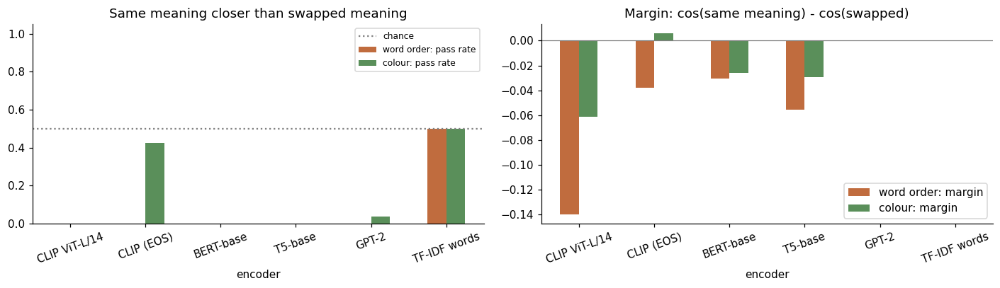

In [28]:
def triplet_test(o, same, changed):
    o, same, changed = l2n(o), l2n(same), l2n(changed)
    s_same, s_changed = (o * same).sum(1), (o * changed).sum(1)
    passed = np.where(np.isclose(s_same, s_changed, atol=1e-6), 0.5, (s_same > s_changed).astype(float))
    return {"pass rate": float(passed.mean()), "margin": float((s_same - s_changed).mean()),
            "cos(orig, changed)": float(s_changed.mean())}


rows = []
for r in REPS:
    o = triplet_test(EMB[r]["order_orig"], EMB[r]["order_same"], EMB[r]["order_changed"])
    c = triplet_test(EMB[r]["colour_orig"], EMB[r]["colour_same"], EMB[r]["colour_changed"])
    rows.append({"encoder": r, "word order: pass rate": o["pass rate"], "word order: margin": o["margin"],
                 "colour: pass rate": c["pass rate"], "colour: margin": c["margin"],
                 "word order: cos(orig, swapped)": o["cos(orig, changed)"], "colour: cos(orig, swapped)": c["cos(orig, changed)"]})
pairs_df = pd.DataFrame(rows).set_index("encoder")
pairs_df.to_csv(TE_OUT / "A_word_order_colour.csv")
display(pairs_df.round(3))

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
pairs_df[["word order: pass rate", "colour: pass rate"]].plot.bar(ax=ax[0], rot=20, color=["#c06c3e", "#5a8f5a"])
ax[0].axhline(0.5, color="gray", ls=":", label="chance"); ax[0].set(title="Same meaning closer than swapped meaning", ylim=(0, 1.05))
ax[0].legend(fontsize=8)
pairs_df[["word order: margin", "colour: margin"]].plot.bar(ax=ax[1], rot=20, color=["#c06c3e", "#5a8f5a"])
ax[1].axhline(0, color="gray", lw=0.8); ax[1].set(title="Margin: cos(same meaning) - cos(swapped)")
plt.tight_layout(); savefig("A4_order_colour"); plt.show()

## How to read the results

* **CKA with CLIP** tells how much a connector would have to change: a low value means BERT, T5 or GPT-2 organise captions very differently from what Stable Diffusion's UNet was trained to read.
* **Paraphrase retrieval** and **scene clustering** measure meaning. If an encoder beats CLIP here, its embeddings carry useful information; if it loses to TF-IDF, it mostly tracks wording.
* **Word order and colour binding** measure composition, a known weak point of text-to-image models. An encoder that passes these triplets clearly more often than CLIP has something specific to offer a connector, and the stress prompts can test whether that shows up in the images.
* All of this is measured on sentence vectors. The diffusion model reads every token state, so these results predict what a connector *could* use, not what images it will produce; that is what the connector experiment tests.

## 20. Combined summary

Part 2's numbers are saved in `results/text_encoders/` and added to `milestone1_summary.json` under `text_encoders`.

In [29]:
te_summary = {
    "encoders": list(TE["encoders"]), "baseline": "TF-IDF words",
    "tokens": tok_table.to_dict("index"),
    "cka_vs_clip": cka["CLIP ViT-L/14"].round(3).to_dict(),
    "paraphrase_retrieval": ret.round(4).to_dict("index"),
    "knn_scene_accuracy": knn.round(4).to_dict(), "knn_majority_class": majority,
    "word_order_and_colour": pairs_df.round(4).to_dict("index"),
}
json.dump(te_summary, open(TE_OUT / "text_encoders_summary.json", "w"), indent=2, default=str)
m1["text_encoders"] = te_summary
json.dump(m1, open(RESULTS / "milestone1_summary.json", "w"), indent=2, default=str)
print(json.dumps(te_summary, indent=2, default=str)[:3000])
print("\nSaved to", TE_OUT, "and added to", RESULTS / "milestone1_summary.json")

{
  "encoders": [
    "CLIP ViT-L/14",
    "BERT-base",
    "T5-base",
    "GPT-2"
  ],
  "baseline": "TF-IDF words",
  "tokens": {
    "CLIP ViT-L/14": {
      "median tokens": 13.0,
      "max tokens": 36.0
    },
    "BERT-base": {
      "median tokens": 13.0,
      "max tokens": 36.0
    },
    "T5-base": {
      "median tokens": 14.0,
      "max tokens": 41.0
    },
    "GPT-2": {
      "median tokens": 11.0,
      "max tokens": 34.0
    }
  },
  "cka_vs_clip": {
    "CLIP ViT-L/14": 1.0,
    "CLIP (EOS)": 0.791,
    "BERT-base": 0.528,
    "T5-base": 0.6,
    "GPT-2": 0.132,
    "TF-IDF words": 0.511
  },
  "paraphrase_retrieval": {
    "CLIP ViT-L/14": {
      "R@1": 0.2145,
      "R@5": 0.412,
      "R@10": 0.5215,
      "median rank": 9.0
    },
    "CLIP (EOS)": {
      "R@1": 0.3395,
      "R@5": 0.5785,
      "R@10": 0.693,
      "median rank": 3.0
    },
    "BERT-base": {
      "R@1": 0.13,
      "R@5": 0.277,
      "R@10": 0.3505,
      "median rank": 29.0
    },
    "T5